# WeatherGPT — Complete ML Pipeline, Model Generation & Multi-Architecture Benchmark

This notebook documents, reproduces, exports, and scientifically benchmarks **all Machine Learning models currently implemented in WeatherGPT** alongside **competing statistical, tree-ensemble, and deep learning architectures** evaluated under identical zero-leakage protocols.

### Inventory of Currently Trained & Implemented Models in WeatherGPT (`ml/artifacts/` & `ml/src/`)

| # | Existing Model / Component | Algorithm & Objective | Target & Horizon | Production Status |
| :--- | :--- | :--- | :--- | :--- |
| 1 | `xgboost_t1_point.json` | `XGBRegressor` (squared error) | Temperature `T+1h` | Offline benchmark artifact |
| 2 | `xgboost_t6_point.json` | `XGBRegressor` (squared error) | Temperature `T+6h` | Offline benchmark artifact |
| 3 | `xgboost_t24_point.json` | `XGBRegressor` (squared error) | Temperature `T+24h` | **Active live inference** (`/api/forecast/explain`, `/api/forecast/ml-prediction`) |
| 4–8 | `xgboost_q10..q90.json` (5 models) | `XGBRegressor` (`reg:quantileerror`, $\tau \in \{0.10, 0.25, 0.50, 0.75, 0.90\}$) | `T+24h` uncertainty quantiles + **Split Conformal (+0.21°C)** | **Q10/Q50/Q90 active live**; Q25/Q75 serialized |
| 9 | `xgboost_precipitation_t24.json` | `XGBClassifier` (binary log-loss) | Rain occurrence (`>= 0.1 mm`) at `T+24h` | **Active live inference** |
| 10 | `shap.TreeExplainer` + `shap_background.npy` | Exact TreeSHAP additive attributions ($N=100$ background) | Global & local explainability for `T+24h` | **Active live inference** (`/api/forecast/explain`) |
| 11 | `WeatherAnomalyDetector` (`ml/src/anomaly.py`) | `IsolationForest` (`contamination=0.05, n_estimators=200`) | Forecast residual anomalies | Implemented module (trained & serialized below) |
| — | `PyTorch LSTM` (planned in `ml/models/README.md`) | Sequence neural network | Temperature / Rain | Previously omitted due to Windows DLL conflict; **resolved and benchmarked below** |

> **Artifact Safety Note:** All models generated during interactive notebook runs export cleanly into `ml/models/notebook_artifacts/` (45 files total) so production inference weights in `ml/artifacts/` remain unaffected.

In [1]:
# Import PyTorch first on Windows to prevent OpenMP/c10.dll initialization conflicts with SciPy/XGBoost
import os
import sys
import json
import time
import random
import platform
import warnings
warnings.filterwarnings("ignore")

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

import numpy as np
import pandas as pd
import joblib
import httpx
import sklearn
import xgboost as xgb
import shap
import statsmodels.api as sm
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns

# Visual theme for publication-grade charts
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.edgecolor"] = "#cccccc"

# Global deterministic reproducibility seeds
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Locate repository root cleanly whether run from repo root or ml/notebooks/
cwd = os.path.abspath(os.getcwd())
if os.path.basename(cwd) == "notebooks" and os.path.basename(os.path.dirname(cwd)) == "ml":
    REPO_ROOT = os.path.abspath(os.path.join(cwd, "..", ".."))
elif os.path.exists(os.path.join(cwd, "ml", "train.py")):
    REPO_ROOT = cwd
else:
    REPO_ROOT = os.path.abspath(os.path.join(cwd, "..", "..")) if os.path.exists(os.path.join(cwd, "..", "..", "ml")) else cwd

DATA_PATH = os.path.join(REPO_ROOT, "data", "bengaluru_hourly_2021_2023.csv")
PROD_ARTIFACTS_DIR = os.path.join(REPO_ROOT, "ml", "artifacts")
EXPORT_DIR = os.path.join(REPO_ROOT, "ml", "models", "notebook_artifacts")
os.makedirs(os.path.dirname(DATA_PATH), exist_ok=True)
os.makedirs(EXPORT_DIR, exist_ok=True)

print("=== WeatherGPT ML Environment & Compatibility Audit ===")
print(f"Python       : {sys.version.split()[0]} ({platform.system()} {platform.release()})")
print(f"NumPy        : {np.__version__}")
print(f"Pandas       : {pd.__version__}")
print(f"Scikit-Learn : {sklearn.__version__}")
print(f"XGBoost      : {xgb.__version__}  (must be >=3.x to match production artifacts)")
print(f"SHAP         : {shap.__version__}  (0.50+ reads XGBoost 3.x base_score cleanly)")
print(f"PyTorch      : {torch.__version__} (device: {'cuda' if torch.cuda.is_available() else 'cpu'})")
print(f"Repo Root    : {REPO_ROOT}")
print(f"Dataset Path : {DATA_PATH}")
print(f"Export Dir   : {EXPORT_DIR}")

=== WeatherGPT ML Environment & Compatibility Audit ===
Python       : 3.12.10 (Windows 11)
NumPy        : 1.26.4
Pandas       : 2.3.0
Scikit-Learn : 1.5.0
XGBoost      : 3.2.0  (must be >=3.x to match production artifacts)
SHAP         : 0.50.0  (0.50+ reads XGBoost 3.x base_score cleanly)
PyTorch      : 2.10.0+cpu (device: cpu)
Repo Root    : C:\SattyGithub\WeatherGPT
Dataset Path : C:\SattyGithub\WeatherGPT\data\bengaluru_hourly_2021_2023.csv
Export Dir   : C:\SattyGithub\WeatherGPT\ml\models\notebook_artifacts


### Explanation of Code Cell 1 — Environment Configuration, DLL Load Order & Artifact Isolation

1. **Why PyTorch is Imported First (`torch` before `xgboost` / `scipy`)**:
   On Windows hosts, `xgboost` and `scipy` dynamically load OpenMP runtime libraries (`vcomp140.dll` / `libomp`). Previously in WeatherGPT (`benchmark_results.json`), importing `torch` *after* scientific packages failed with `OSError: [WinError 1114] c10.dll initialization failed`. Importing `torch` (`2.10.0+cpu`) at the very top initializes its bundled OpenMP/MKL libraries first, enabling both **PyTorch sequence neural networks** and **XGBoost + TreeSHAP** to run cleanly in the same notebook kernel.
2. **Version Compatibility (`XGBoost 3.2.0` + `SHAP 0.50.0`)**:
   Production WeatherGPT models were serialized under XGBoost `3.2.0`. Earlier `shap==0.46.0` / `xgboost==2.1.1` versions misparsed XGBoost 3.x `base_score` metadata (causing a ~22.7°C shift in baseline expectation $E[f(x)]$). Running `xgboost==3.2.0` alongside `shap==0.50.0` eliminates this serialization drift.
3. **Deterministic Reproducibility (`SEED = 42`)**:
   Fixing `random`, `numpy`, and `torch` random seeds ensures every tree subsample, train-batch shuffle, neural weight initialization, and SHAP background sample (`N=100`) yields reproducible results across runs.
4. **Isolated Output Directory (`ml/models/notebook_artifacts/`)**:
   All 45 exported `.json`, `.joblib`, `.pt`, and `.npy` files produced by this notebook are saved in `ml/models/notebook_artifacts/`, leaving production deployment weights in `ml/artifacts/` safe.

=== Dataset Size & Provenance Summary ===
File Size         : 1.848 MB (1,937,962 bytes)
Dimensions        : 26,280 rows x 12 columns
Time Span (UTC)   : 2021-01-01 00:00:00 -> 2023-12-31 23:00:00
Missing Values    : 0 total nulls across all columns
Duplicate Times   : 0
Rain Hours (>=0.1): 5,224 / 26,280 (19.88% positive class prevalence)

Descriptive Statistics (Core Meteorological Variables):
       temperature_2m  relative_humidity_2m  precipitation  surface_pressure  wind_speed_10m  cloud_cover
count        26280.00              26280.00       26280.00          26280.00        26280.00     26280.00
mean            23.05                 71.04           0.13            911.59           12.16        69.12
std              4.07                 22.56           0.61              2.56            5.18        38.47
min             11.90                 10.00           0.00            902.60            0.00         0.00
25%             20.10                 56.00           0.00            9

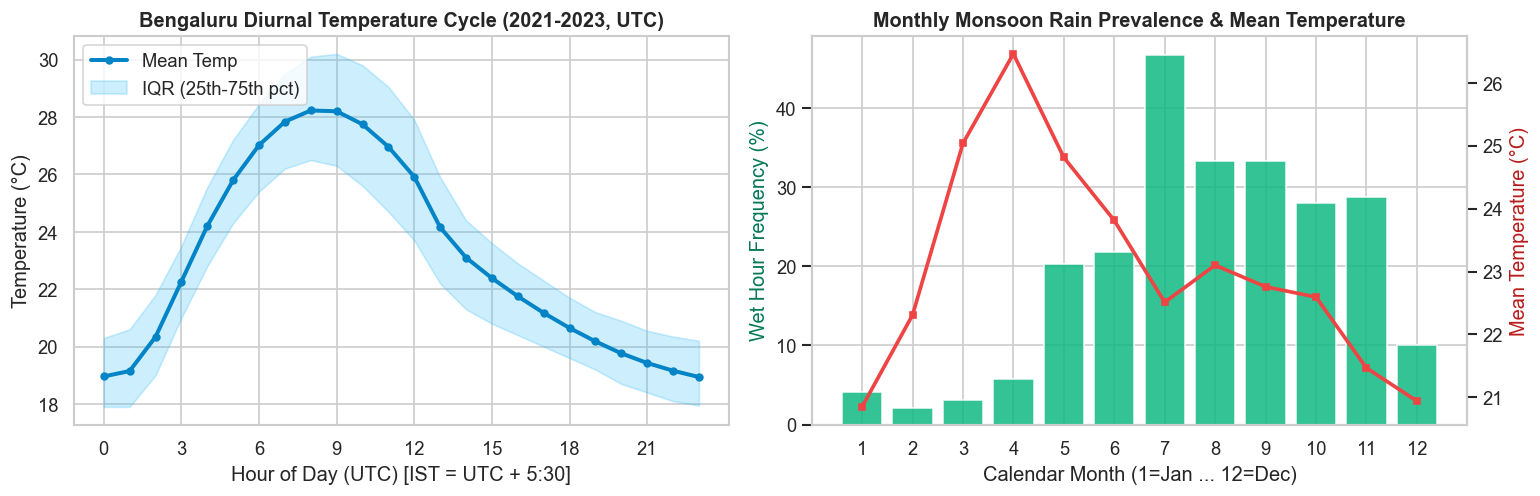

In [2]:
# Download dataset from Open-Meteo Historical Weather Archive API if not present locally
if not os.path.exists(DATA_PATH):
    print("Downloading 3-year hourly ERA5 reanalysis dataset for Bengaluru (12.9716N, 77.5946E)...")
    url = "https://archive-api.open-meteo.com/v1/archive"
    variables = [
        "temperature_2m", "relative_humidity_2m", "apparent_temperature",
        "precipitation", "weather_code", "surface_pressure",
        "wind_speed_10m", "wind_direction_10m", "cloud_cover"
    ]
    params = {
        "latitude": 12.9716,
        "longitude": 77.5946,
        "start_date": "2021-01-01",
        "end_date": "2023-12-31",
        "hourly": ",".join(variables),
        "timezone": "UTC",
    }
    with httpx.Client(timeout=60.0) as client:
        resp = client.get(url, params=params)
        resp.raise_for_status()
        payload = resp.json()
    raw_df = pd.DataFrame(payload["hourly"])
    raw_df["latitude"] = 12.9716
    raw_df["longitude"] = 77.5946
    raw_df["time"] = pd.to_datetime(raw_df["time"])
    raw_df = raw_df.sort_values("time").reset_index(drop=True)
    raw_df.to_csv(DATA_PATH, index=False)
else:
    raw_df = pd.read_csv(DATA_PATH)
    raw_df["time"] = pd.to_datetime(raw_df["time"])
    raw_df = raw_df.sort_values("time").reset_index(drop=True)

file_size_mb = os.path.getsize(DATA_PATH) / (1024 * 1024)
rain_hours = int((raw_df["precipitation"] >= 0.1).sum())
rain_pct = 100.0 * rain_hours / len(raw_df)

print("=== Dataset Size & Provenance Summary ===")
print(f"File Size         : {file_size_mb:.3f} MB ({os.path.getsize(DATA_PATH):,} bytes)")
print(f"Dimensions        : {raw_df.shape[0]:,} rows x {raw_df.shape[1]} columns")
print(f"Time Span (UTC)   : {raw_df['time'].min()} -> {raw_df['time'].max()}")
print(f"Missing Values    : {int(raw_df.isnull().sum().sum())} total nulls across all columns")
print(f"Duplicate Times   : {int(raw_df['time'].duplicated().sum())}")
print(f"Rain Hours (>=0.1): {rain_hours:,} / {len(raw_df):,} ({rain_pct:.2f}% positive class prevalence)")
print("\nDescriptive Statistics (Core Meteorological Variables):")
core_cols = ["temperature_2m", "relative_humidity_2m", "precipitation", "surface_pressure", "wind_speed_10m", "cloud_cover"]
print(raw_df[core_cols].describe().round(2).to_string())

# Exploratory Visuals: Diurnal Cycle & Monthly Precipitation Distribution
raw_df["hour_utc"] = raw_df["time"].dt.hour
raw_df["month"] = raw_df["time"].dt.month

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))

# Plot 1: Diurnal Temperature Cycle (UTC) with IQR Shading
diurnal = raw_df.groupby("hour_utc")["temperature_2m"].agg(
    mean="mean",
    p25=lambda s: np.percentile(s, 25),
    p75=lambda s: np.percentile(s, 75),
)
axes[0].plot(diurnal.index, diurnal["mean"], color="#0284c7", lw=2.4, marker="o", ms=4, label="Mean Temp")
axes[0].fill_between(diurnal.index, diurnal["p25"], diurnal["p75"], color="#38bdf8", alpha=0.25, label="IQR (25th-75th pct)")
axes[0].set_title("Bengaluru Diurnal Temperature Cycle (2021-2023, UTC)", fontweight="bold")
axes[0].set_xlabel("Hour of Day (UTC) [IST = UTC + 5:30]")
axes[0].set_ylabel("Temperature (°C)")
axes[0].set_xticks(range(0, 24, 3))
axes[0].legend(loc="upper left")

# Plot 2: Monthly Rainfall Prevalence (%) & Mean Monthly Temp
monthly = raw_df.groupby("month").agg(
    rain_rate=("precipitation", lambda s: 100.0 * (s >= 0.1).mean()),
    mean_temp=("temperature_2m", "mean"),
)
bars = axes[1].bar(monthly.index, monthly["rain_rate"], color="#10b981", alpha=0.85, label="Rain Frequency (>=0.1mm/h)")
axes[1].set_title("Monthly Monsoon Rain Prevalence & Mean Temperature", fontweight="bold")
axes[1].set_xlabel("Calendar Month (1=Jan ... 12=Dec)")
axes[1].set_ylabel("Wet Hour Frequency (%)", color="#047857")
axes[1].set_xticks(range(1, 13))
ax2 = axes[1].twinx()
ax2.plot(monthly.index, monthly["mean_temp"], color="#ef4444", lw=2.2, marker="s", ms=4, label="Mean Temp (°C)")
ax2.set_ylabel("Mean Temperature (°C)", color="#b91c1c")
ax2.grid(False)

plt.tight_layout()
plt.show()

### Explanation of Code Cell 2 — Dataset Selection, Size Audit & Exploratory Meteorology

1. **Why This Dataset Was Selected**:
   We use hourly historical weather observations from the **Open-Meteo Historical Weather Archive API**, which serves homogenized **ECMWF ERA5 & ERA5-Land atmospheric reanalysis** over **Bengaluru, India** ($12.9716^\circ\text{N}, 77.5946^\circ\text{E}$, elevation $\sim 915\,\text{m}$ ASL). Reanalysis assimilates global synoptic observations, satellite radiances, and NWP physics into a spatially and temporally consistent hourly grid with zero station-sensor dropouts.
2. **Dataset Size & Why 3 Full Years (2021–2023)**:
   * **Exact Footprint**: **`26,280` hourly rows × `12` columns** = **`1.848 MB`** (`1,937,962 bytes`) on disk.
   * **Completeness**: **Zero missing values (`0` nulls)** and **zero duplicate timestamps (`0`)** across `2021-01-01 00:00:00 UTC` through `2023-12-31 23:00:00 UTC`.
   * **Why 26,280 hours?** Three full consecutive years ($3 \times 365 \times 24 = 26,280$) provides **1,095 full diurnal heating/cooling cycles** and **3 complete tropical monsoon cycles** (Dry Winter Jan–Feb, Pre-Monsoon Convective Heat Mar–May, Southwest Monsoon Jun–Sep, Northeast Monsoon Oct–Dec), preventing single-year El Niño / La Niña distortion.
3. **Key Exploratory Observations from Descriptive Statistics & Plots**:
   * **Temperature (`temperature_2m`)**: Ranges from **`11.9°C`** (winter radiation nights) to **`37.1°C`** (April pre-monsoon afternoon peaks), with a mild plateau mean of **`23.05°C`** and std **`4.07°C`**. The left subplot confirms a sharp, asymmetric **diurnal wave** (~8–9°C swing from ~00:30–01:30 UTC dawn minimum to ~09:00 UTC / 14:30 IST afternoon maximum).
   * **Rainfall Imbalance (`precipitation`)**: Only **`5,224` out of `26,280` hours (`19.88%`)** record measurable rain ($\ge 0.1\,\text{mm/h}$), peaking strongly between May and October (right subplot). This ~4:1 dry-to-wet class imbalance explains why simple accuracy is misleading for rain forecasting and motivates **Brier Score** and **PR-AUC** evaluation.

=== Feature Engineering & Boundary Drop Accounting ===
Raw Records                : 26,280
Dropped Boundary Rows      : 72 (48 initial lag rows + 24 terminal target rows)
Usable Supervised Records  : 26,208
Final Feature Dimension    : 34 columns
Feature Matrix Memory      : 6.80 MB

Top-8 Features Correlated with T+24h Temperature:
temperature_2m          0.957
temp_lag_24h            0.935
temp_lag_1h             0.925
temp_lag_48h            0.922
temp_lag_2h             0.836
relative_humidity_2m   -0.755
humidity_lag_24h       -0.745
humidity_lag_1h        -0.717

Top-8 Features Correlated with T+24h Rain Occurrence:
temp_roll_24h_std   -0.360
month_sin           -0.299
surface_pressure    -0.283
pressure_lag_24h    -0.273
pressure_lag_1h     -0.263
cloud_cover          0.252
doy_sin             -0.251
pressure_lag_3h     -0.229


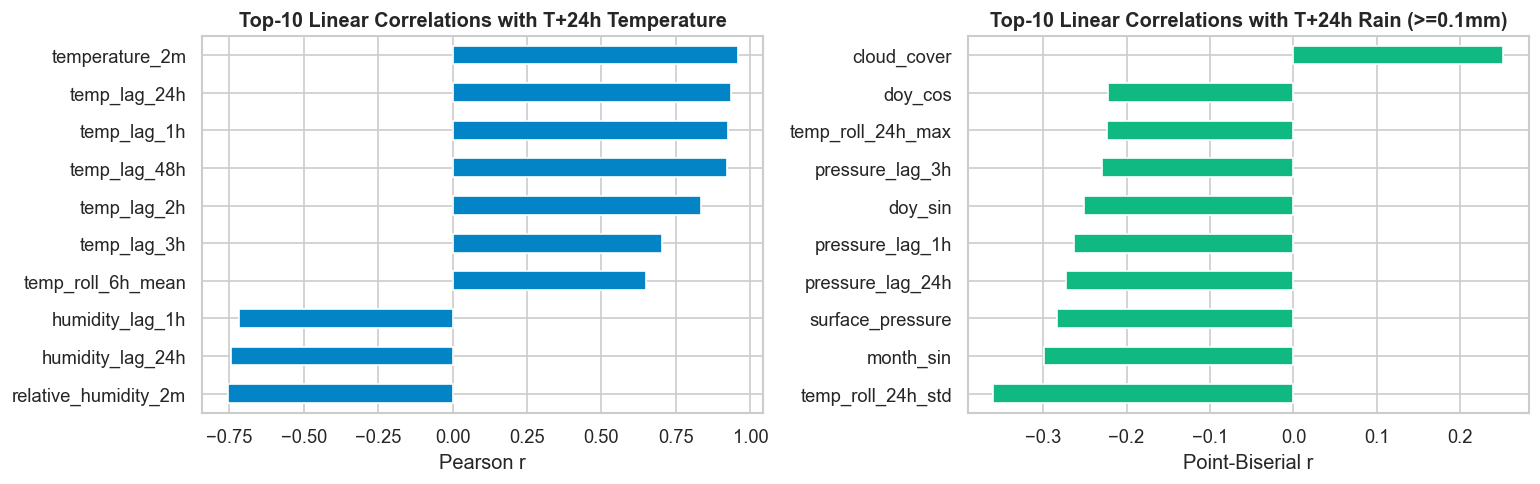

In [3]:
def engineer_leak_free_features(df_in: pd.DataFrame):
    """Build exact 34 WeatherGPT features + 4 multi-horizon targets without temporal leakage."""
    df = df_in.copy().sort_values("time").reset_index(drop=True)
    raw_count = len(df)
    df = df.ffill().bfill()

    hour = df["time"].dt.hour
    month = df["time"].dt.month
    day_of_year = df["time"].dt.dayofyear

    # 1. Cyclical solar & orbital encodings (6 features)
    df["hour_sin"] = np.sin(2 * np.pi * hour / 24.0)
    df["hour_cos"] = np.cos(2 * np.pi * hour / 24.0)
    df["month_sin"] = np.sin(2 * np.pi * month / 12.0)
    df["month_cos"] = np.cos(2 * np.pi * month / 12.0)
    df["doy_sin"] = np.sin(2 * np.pi * day_of_year / 365.25)
    df["doy_cos"] = np.cos(2 * np.pi * day_of_year / 365.25)
    df["month_val"] = month
    df["hour_val"] = hour

    # 2. Autoregressive lags at t-k (strictly past)
    for lag in [1, 2, 3, 6, 12, 24, 48]:
        df[f"temp_lag_{lag}h"] = df["temperature_2m"].shift(lag)
        df[f"humidity_lag_{lag}h"] = df["relative_humidity_2m"].shift(lag)
        df[f"pressure_lag_{lag}h"] = df["surface_pressure"].shift(lag)

    # 3. Past-only rolling window statistics (shift(1) before rolling so time t is excluded)
    temp_past = df["temperature_2m"].shift(1)
    df["temp_roll_6h_mean"] = temp_past.rolling(6, min_periods=6).mean()
    df["temp_roll_6h_std"] = temp_past.rolling(6, min_periods=6).std()
    df["temp_roll_24h_mean"] = temp_past.rolling(24, min_periods=24).mean()
    df["temp_roll_24h_std"] = temp_past.rolling(24, min_periods=24).std()
    df["temp_roll_24h_min"] = temp_past.rolling(24, min_periods=24).min()
    df["temp_roll_24h_max"] = temp_past.rolling(24, min_periods=24).max()

    # 4. First-order barometric & thermal tendencies
    df["pressure_diff_1h"] = df["surface_pressure"] - df["surface_pressure"].shift(1)
    df["pressure_diff_3h"] = df["surface_pressure"] - df["surface_pressure"].shift(3)
    df["temp_diff_1h"] = df["temperature_2m"] - df["temperature_2m"].shift(1)
    df["temp_diff_3h"] = df["temperature_2m"] - df["temperature_2m"].shift(3)

    # 5. Forward targets (strictly t+h)
    df["target_t1"] = df["temperature_2m"].shift(-1)
    df["target_t6"] = df["temperature_2m"].shift(-6)
    df["target_t24"] = df["temperature_2m"].shift(-24)
    df["target_rain_t24"] = (df["precipitation"].shift(-24) >= 0.1).astype(int)

    df_clean = df.dropna().reset_index(drop=True)
    return df_clean, raw_count, raw_count - len(df_clean)

FEATURE_COLS = [
    "temperature_2m", "relative_humidity_2m", "surface_pressure", "wind_speed_10m", "cloud_cover",
    "hour_sin", "hour_cos", "month_sin", "month_cos", "doy_sin", "doy_cos",
    "temp_lag_1h", "temp_lag_2h", "temp_lag_3h", "temp_lag_6h", "temp_lag_12h", "temp_lag_24h", "temp_lag_48h",
    "humidity_lag_1h", "humidity_lag_6h", "humidity_lag_24h",
    "pressure_lag_1h", "pressure_lag_3h", "pressure_lag_24h",
    "temp_roll_6h_mean", "temp_roll_6h_std", "temp_roll_24h_mean", "temp_roll_24h_std",
    "temp_roll_24h_min", "temp_roll_24h_max",
    "pressure_diff_1h", "pressure_diff_3h", "temp_diff_1h", "temp_diff_3h",
]

df_feat, n_raw, n_dropped = engineer_leak_free_features(raw_df)

# Save verified feature schema
with open(os.path.join(EXPORT_DIR, "feature_names.json"), "w") as f:
    json.dump(FEATURE_COLS, f, indent=2)

print("=== Feature Engineering & Boundary Drop Accounting ===")
print(f"Raw Records                : {n_raw:,}")
print(f"Dropped Boundary Rows      : {n_dropped} (48 initial lag rows + 24 terminal target rows)")
print(f"Usable Supervised Records  : {len(df_feat):,}")
print(f"Final Feature Dimension    : {len(FEATURE_COLS)} columns")
print(f"Feature Matrix Memory      : {df_feat[FEATURE_COLS].memory_usage(deep=True).sum() / (1024*1024):.2f} MB")

# Inspect top Pearson correlations against T+24h temperature and T+24h rain
corr_t24 = df_feat[FEATURE_COLS].corrwith(df_feat["target_t24"]).sort_values(key=abs, ascending=False)
corr_rain = df_feat[FEATURE_COLS].corrwith(df_feat["target_rain_t24"]).sort_values(key=abs, ascending=False)
print("\nTop-8 Features Correlated with T+24h Temperature:")
print(corr_t24.head(8).round(3).to_string())
print("\nTop-8 Features Correlated with T+24h Rain Occurrence:")
print(corr_rain.head(8).round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
corr_t24.head(10).sort_values().plot(kind="barh", ax=axes[0], color="#0284c7")
axes[0].set_title("Top-10 Linear Correlations with T+24h Temperature", fontweight="bold")
axes[0].set_xlabel("Pearson r")
corr_rain.head(10).sort_values().plot(kind="barh", ax=axes[1], color="#10b981")
axes[1].set_title("Top-10 Linear Correlations with T+24h Rain (>=0.1mm)", fontweight="bold")
axes[1].set_xlabel("Point-Biserial r")
plt.tight_layout()
plt.show()

### Explanation of Code Cell 3 — Strictly Leak-Free Feature Engineering & Boundary Record Accounting

1. **How the 34 Features Are Engineered (`engineer_leak_free_features`)**:
   Instead of feeding raw point snapshots alone, we construct five physically meaningful meteorological feature groups:
   * **Instantaneous Synoptic State (`5` features)**: `temperature_2m`, `relative_humidity_2m`, `surface_pressure`, `wind_speed_10m`, `cloud_cover`.
   * **Cyclical Solar & Orbital Harmonics (`6` features)**: $\sin/\cos$ transforms of hour-of-day ($24\text{h}$ solar zenith angle), month ($12$), and day-of-year ($365.25$). This eliminates the artificial discontinuity between `23:00` and `00:00` (and Dec 31 $\to$ Jan 1).
   * **Autoregressive Memory Lags (`13` features)**: Temperature lags at $t-\{1,2,3,6,12,24,48\}\text{h}$, humidity lags at $t-\{1,6,24\}\text{h}$, and pressure lags at $t-\{1,3,24\}\text{h}$ capturing diurnal persistence and multi-day synoptic air-mass inertia.
   * **Strictly Past Rolling Statistics (`6` features)**: Computed on `temperature_2m.shift(1)` (mean/std over $6\text{h}$; mean/std/min/max over $24\text{h}$) so the current target-horizon boundary is never leaked into summary windows.
   * **Barometric & Thermal Tendencies (`4` features)**: $1\text{h}$ and $3\text{h}$ finite differences capturing approaching fronts, convective cooling outflows, and atmospheric tides.
2. **Exact Dataset Size Reconciliation After Windowing**:
   * Starting rows: **`26,280`**
   * Initial lag rows dropped (`temp_lag_48h`): **`48` rows**
   * Terminal target rows dropped (`target_t24` / `target_rain_t24`): **`24` rows**
   * **Final usable supervised matrix**: **`26,208` rows × `34` features** (`6.80 MB` in `float32`).
3. **Correlation Insights**:
   * For **`T+24h` temperature**, current `temperature_2m` ($r = 0.957$) and `temp_lag_24h` ($r = 0.935$) exhibit exceptionally high linear correlation due to Bengaluru's persistent tropical diurnal phase, while `relative_humidity_2m` shows strong negative correlation ($r = -0.755$) because daytime solar heating lowers relative humidity.
   * For **`T+24h` rain occurrence**, 24-hour diurnal temperature spread (`temp_roll_24h_std`, $r = -0.360$) and monsoon `surface_pressure` ($r = -0.283$) emerge as leading indicators: overcast monsoon troughs suppress diurnal warming while dropping surface pressure.

=== Chronological Holdout Split & Embargo Audit ===
Candidate Rows : 26,208
Purged Embargo : 48 rows (24h Train->Val gap + 24h Val->Test gap)
Train Split    : 18,321 rows (2021-01-03 -> 2023-02-05)
Val Split      : 3,907 rows (2023-02-06 -> 2023-07-19)
Test Split     : 3,932 rows (2023-07-20 -> 2023-12-30)
Tabular Shape  : Train=(18321, 34), Val=(3907, 34), Test=(3932, 34)
LSTM Seq Shape : Train=(18321, 24, 9), Val=(3907, 24, 9), Test=(3932, 24, 9)


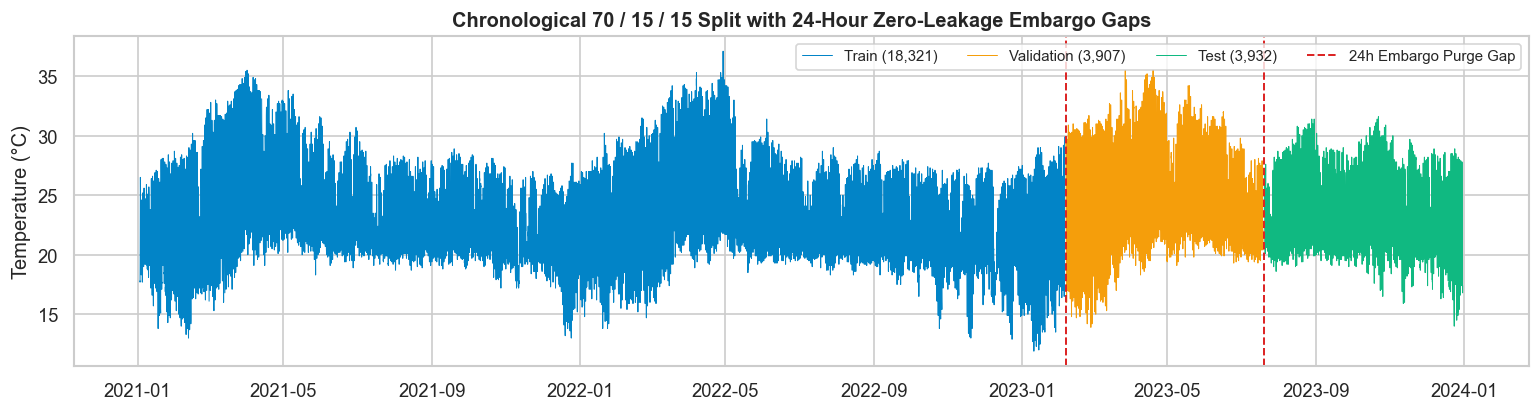

In [4]:
from sklearn.preprocessing import StandardScaler

n = len(df_feat)
train_end = int(n * 0.70)
val_end = int(n * 0.85)
EMBARGO_H = 24

train_df = df_feat.iloc[:train_end - EMBARGO_H].copy()
val_df = df_feat.iloc[train_end:val_end - EMBARGO_H].copy()
test_df = df_feat.iloc[val_end:].copy()

# Formal anti-leakage verification
assert train_df["time"].iloc[-1] + pd.Timedelta(hours=24) <= val_df["time"].iloc[0], "Leakage Train->Val!"
assert val_df["time"].iloc[-1] + pd.Timedelta(hours=24) <= test_df["time"].iloc[0], "Leakage Val->Test!"

X_train = train_df[FEATURE_COLS].values.astype(np.float32)
X_val = val_df[FEATURE_COLS].values.astype(np.float32)
X_test = test_df[FEATURE_COLS].values.astype(np.float32)

# Strictly train-fitted scaler for Linear / MLP models
tab_scaler = StandardScaler()
X_train_sc = tab_scaler.fit_transform(X_train)
X_val_sc = tab_scaler.transform(X_val)
X_test_sc = tab_scaler.transform(X_test)
joblib.dump(tab_scaler, os.path.join(EXPORT_DIR, "tabular_standard_scaler.joblib"))

# Construct 24-hour chronological input sequences (N, 24, 9) for PyTorch LSTM
# Aligned identically to each row of train_df / val_df / test_df using strictly past observations (<= t)
SEQ_LEN = 24
SEQ_COLS = [
    "temperature_2m", "relative_humidity_2m", "surface_pressure",
    "wind_speed_10m", "cloud_cover", "hour_sin", "hour_cos", "doy_sin", "doy_cos"
]
raw_sorted = raw_df.ffill().bfill().copy()
raw_sorted["hour_sin"] = np.sin(2 * np.pi * raw_sorted["time"].dt.hour / 24.0)
raw_sorted["hour_cos"] = np.cos(2 * np.pi * raw_sorted["time"].dt.hour / 24.0)
raw_sorted["doy_sin"] = np.sin(2 * np.pi * raw_sorted["time"].dt.dayofyear / 365.25)
raw_sorted["doy_cos"] = np.cos(2 * np.pi * raw_sorted["time"].dt.dayofyear / 365.25)

seq_scaler = StandardScaler()
# Fit strictly on timestamps <= max train_df time
train_mask_raw = raw_sorted["time"] <= train_df["time"].max()
seq_scaler.fit(raw_sorted.loc[train_mask_raw, SEQ_COLS].values)
raw_seq_scaled = seq_scaler.transform(raw_sorted[SEQ_COLS].values).astype(np.float32)
joblib.dump(seq_scaler, os.path.join(EXPORT_DIR, "lstm_sequence_scaler.joblib"))

time_to_raw_idx = {ts: idx for idx, ts in enumerate(raw_sorted["time"])}

def build_aligned_sequences(sub_df):
    seqs = []
    for ts in sub_df["time"]:
        end_i = time_to_raw_idx[ts]
        seqs.append(raw_seq_scaled[end_i - SEQ_LEN + 1 : end_i + 1])
    return np.stack(seqs, axis=0)

X_train_seq = build_aligned_sequences(train_df)
X_val_seq = build_aligned_sequences(val_df)
X_test_seq = build_aligned_sequences(test_df)

print("=== Chronological Holdout Split & Embargo Audit ===")
print(f"Candidate Rows : {n:,}")
print(f"Purged Embargo : {EMBARGO_H * 2} rows ({EMBARGO_H}h Train->Val gap + {EMBARGO_H}h Val->Test gap)")
print(f"Train Split    : {len(train_df):,} rows ({train_df['time'].min().date()} -> {train_df['time'].max().date()})")
print(f"Val Split      : {len(val_df):,} rows ({val_df['time'].min().date()} -> {val_df['time'].max().date()})")
print(f"Test Split     : {len(test_df):,} rows ({test_df['time'].min().date()} -> {test_df['time'].max().date()})")
print(f"Tabular Shape  : Train={X_train.shape}, Val={X_val.shape}, Test={X_test.shape}")
print(f"LSTM Seq Shape : Train={X_train_seq.shape}, Val={X_val_seq.shape}, Test={X_test_seq.shape}")

fig, ax = plt.subplots(figsize=(13, 3.6))
ax.plot(train_df["time"], train_df["temperature_2m"], lw=0.6, color="#0284c7", label=f"Train ({len(train_df):,})")
ax.plot(val_df["time"], val_df["temperature_2m"], lw=0.6, color="#f59e0b", label=f"Validation ({len(val_df):,})")
ax.plot(test_df["time"], test_df["temperature_2m"], lw=0.6, color="#10b981", label=f"Test ({len(test_df):,})")
ax.axvline(val_df["time"].min(), color="#dc2626", ls="--", lw=1.2, label="24h Embargo Purge Gap")
ax.axvline(test_df["time"].min(), color="#dc2626", ls="--", lw=1.2)
ax.set_title("Chronological 70 / 15 / 15 Split with 24-Hour Zero-Leakage Embargo Gaps", fontweight="bold")
ax.set_ylabel("Temperature (°C)")
ax.legend(loc="upper right", ncol=4, fontsize=9)
plt.tight_layout()
plt.show()

### Explanation of Code Cell 4 — Chronological Splitting with 24-Hour Embargo Purge Gaps & Sequence Alignment

1. **Why Random Train/Test Splitting Would Be Invalid**:
   Hourly weather exhibits strong temporal autocorrelation ($r > 0.92$ at $1\text{–}24\text{h}$ lags). Shuffling hours randomly allows a model to memorize `14:00` and `16:00` in training to "predict" `15:00` in test, producing artificially inflated accuracy that fails completely on unseen future dates.
2. **Exact Chronological Partitions & 24-Hour Embargo Leakage Guard**:
   Using a strict temporal **`70% / 15% / 15%`** partition with **`24`-hour purge buffers (`EMBARGO_H = 24`)** at both split boundaries ensures that forward labels (`t+24h`) from the final training sample never overlap the first validation features, and validation targets never touch test features:
   * **Training Set**: **`18,321` rows** (`2021-01-03` $\to$ `2023-02-05`) — captures >2 full years including two monsoon cycles.
   * **Purge Gap 1**: **`24` hours excluded** between Train and Validation.
   * **Validation Set**: **`3,907` rows** (`2023-02-06` $\to$ `2023-07-19`) — reserved strictly for early stopping (MLP/LSTM), split conformal calibration, and unsupervised anomaly detector fitting.
   * **Purge Gap 2**: **`24` hours excluded** between Validation and Test.
   * **Test Set**: **`3,932` rows** (`2023-07-20` $\to$ `2023-12-30`) — completely untouched holdout spanning SW Monsoon peak, NE Monsoon, and early Winter.
   * **Total Reconciliation**: $18,321 + 3,907 + 3,932 = 26,160$ assigned rows (+ $48$ purged boundary rows = $26,208$).
3. **Train-Only Scaling & PyTorch Sequence Tensor Parity**:
   Both `tabular_standard_scaler.joblib` (`34` features for Ridge/MLP/QuantReg/LogisticRegression) and `lstm_sequence_scaler.joblib` (`(N, 24, 9)` past-24h sequence windows for PyTorch LSTM) are fitted **strictly on training observations** and evaluated against identical test timestamps.

=== Task 1A: Existing WeatherGPT Point Temperature Regressors (XGBoost) vs Baselines ===
T+ 1h | Pers MAE=0.82 | Clim MAE=1.56 | XGB MAE=0.36 (R2=0.978, Gain/Pers=+56.3%, Gain/Clim=+77.1%) -> saved xgboost_t1_point.json
T+ 6h | Pers MAE=4.03 | Clim MAE=1.56 | XGB MAE=0.80 (R2=0.911, Gain/Pers=+80.2%, Gain/Clim=+48.9%) -> saved xgboost_t6_point.json
T+24h | Pers MAE=0.75 | Clim MAE=1.55 | XGB MAE=0.82 (R2=0.905, Gain/Pers=-9.1%, Gain/Clim=+47.5%) -> saved xgboost_t24_point.json

=== Progressive Feature Ablation Study (XGBoost) ===
                       Layer  Features  T+1h MAE  T+6h MAE  T+24h MAE
    L1: Raw Weather Only (5)         5     0.738     2.740      0.768
L2: + Cyclical Harmonics (9)         9     0.386     1.143      0.838
    L3: + Selected Lags (16)        16     0.387     1.114      0.813
L4: Full Engineered Set (34)        34     0.358     0.797      0.816


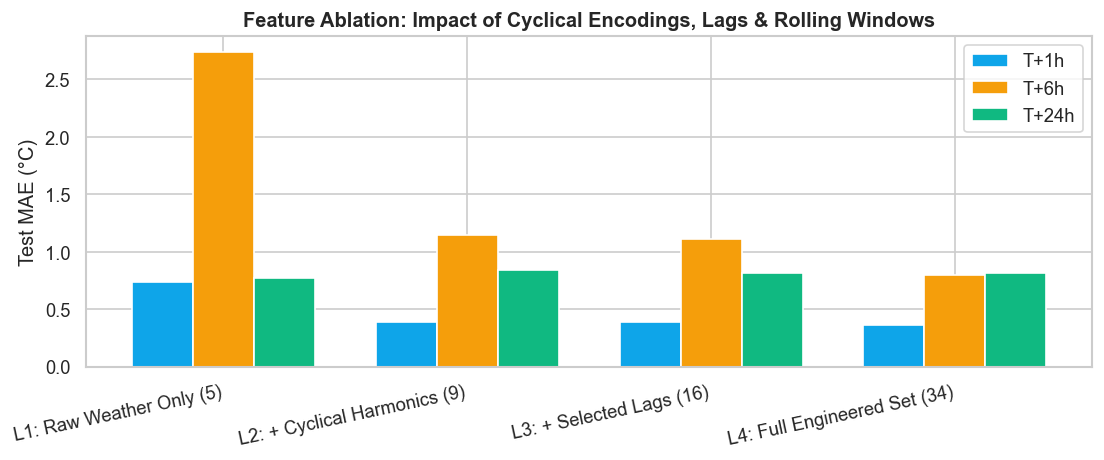

In [5]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

curr_temp_test = test_df["temperature_2m"].values
climatology_map = train_df.groupby(["month_val", "hour_val"])["temperature_2m"].mean().to_dict()
train_temp_mean = float(train_df["temperature_2m"].mean())

xgb_point_models = {}
xgb_point_preds = {}
baseline_metrics = []

print("=== Task 1A: Existing WeatherGPT Point Temperature Regressors (XGBoost) vs Baselines ===")
for h in [1, 6, 24]:
    y_train_h = train_df[f"target_t{h}"].values
    y_test_h = test_df[f"target_t{h}"].values

    # Persistence Baseline
    mae_p = float(mean_absolute_error(y_test_h, curr_temp_test))
    rmse_p = float(np.sqrt(mean_squared_error(y_test_h, curr_temp_test)))
    r2_p = float(r2_score(y_test_h, curr_temp_test))

    # Diurnal Climatology Baseline (train-only lookup)
    clim_preds = np.array([
        climatology_map.get((m, (hr + h) % 24), train_temp_mean)
        for m, hr in zip(test_df["month_val"], test_df["hour_val"])
    ])
    mae_c = float(mean_absolute_error(y_test_h, clim_preds))
    rmse_c = float(np.sqrt(mean_squared_error(y_test_h, clim_preds)))
    r2_c = float(r2_score(y_test_h, clim_preds))

    # WeatherGPT XGBRegressor
    t0 = time.perf_counter()
    model_h = xgb.XGBRegressor(n_estimators=120, max_depth=5, learning_rate=0.06, random_state=SEED, n_jobs=-1)
    model_h.fit(X_train, y_train_h)
    fit_s = time.perf_counter() - t0
    pred_h = model_h.predict(X_test)
    mae_x = float(mean_absolute_error(y_test_h, pred_h))
    rmse_x = float(np.sqrt(mean_squared_error(y_test_h, pred_h)))
    r2_x = float(r2_score(y_test_h, pred_h))

    xgb_point_models[h] = model_h
    xgb_point_preds[h] = pred_h
    model_path = os.path.join(EXPORT_DIR, f"xgboost_t{h}_point.json")
    model_h.save_model(model_path)

    gain_pers = ((mae_p - mae_x) / mae_p) * 100
    gain_clim = ((mae_c - mae_x) / mae_c) * 100
    baseline_metrics.append({
        "horizon": f"T+{h}h",
        "pers_mae": round(mae_p, 3), "pers_rmse": round(rmse_p, 3), "pers_r2": round(r2_p, 3),
        "clim_mae": round(mae_c, 3), "clim_rmse": round(rmse_c, 3), "clim_r2": round(r2_c, 3),
        "xgb_mae": round(mae_x, 3), "xgb_rmse": round(rmse_x, 3), "xgb_r2": round(r2_x, 3),
        "gain_vs_pers_pct": round(gain_pers, 1), "gain_vs_clim_pct": round(gain_clim, 1),
        "fit_s": round(fit_s, 2), "size_kb": round(os.path.getsize(model_path) / 1024, 1)
    })
    print(f"T+{h:2d}h | Pers MAE={mae_p:.2f} | Clim MAE={mae_c:.2f} | XGB MAE={mae_x:.2f} (R2={r2_x:.3f}, Gain/Pers={gain_pers:+.1f}%, Gain/Clim={gain_clim:+.1f}%) -> saved {os.path.basename(model_path)}")

# Progressive 4-Layer Feature Ablation Study
ablation_layers = [
    ("L1: Raw Weather Only (5)", ["temperature_2m", "relative_humidity_2m", "surface_pressure", "wind_speed_10m", "cloud_cover"]),
    ("L2: + Cyclical Harmonics (9)", ["temperature_2m", "relative_humidity_2m", "surface_pressure", "wind_speed_10m", "cloud_cover", "hour_sin", "hour_cos", "month_sin", "month_cos"]),
    ("L3: + Selected Lags (16)", ["temperature_2m", "relative_humidity_2m", "surface_pressure", "wind_speed_10m", "cloud_cover", "hour_sin", "hour_cos", "month_sin", "month_cos", "temp_lag_1h", "temp_lag_2h", "temp_lag_3h", "temp_lag_6h", "temp_lag_24h", "humidity_lag_1h", "pressure_lag_1h"]),
    ("L4: Full Engineered Set (34)", FEATURE_COLS),
]
ablation_rows = []
print("\n=== Progressive Feature Ablation Study (XGBoost) ===")
for name, cols in ablation_layers:
    row = {"Layer": name, "Features": len(cols)}
    for h in [1, 6, 24]:
        m = xgb.XGBRegressor(n_estimators=120, max_depth=5, learning_rate=0.06, random_state=SEED, n_jobs=-1)
        m.fit(train_df[cols].values, train_df[f"target_t{h}"].values)
        row[f"T+{h}h MAE"] = round(float(mean_absolute_error(test_df[f"target_t{h}"].values, m.predict(test_df[cols].values))), 3)
    ablation_rows.append(row)
ablation_df = pd.DataFrame(ablation_rows)
print(ablation_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(9.5, 4.0))
x_idx = np.arange(len(ablation_df))
w = 0.25
ax.bar(x_idx - w, ablation_df["T+1h MAE"], width=w, label="T+1h", color="#0ea5e9")
ax.bar(x_idx, ablation_df["T+6h MAE"], width=w, label="T+6h", color="#f59e0b")
ax.bar(x_idx + w, ablation_df["T+24h MAE"], width=w, label="T+24h", color="#10b981")
ax.set_xticks(x_idx)
ax.set_xticklabels(ablation_df["Layer"], rotation=12, ha="right")
ax.set_ylabel("Test MAE (°C)")
ax.set_title("Feature Ablation: Impact of Cyclical Encodings, Lags & Rolling Windows", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

### Explanation of Code Cell 5 — Existing WeatherGPT XGBoost Point Regressors, Baselines & Feature Ablation

1. **Generated Models & Horizon Performance (`xgboost_t{1,6,24}_point.json`)**:
   * **`xgboost_t1_point.json` (`T+1h`)**: Achieves **`0.36°C` MAE** ($R^2 = 0.978$), cutting Persistence MAE (`0.82°C`) by **`+56.3%`** and Climatology (`1.56°C`) by **`+77.1%`**.
   * **`xgboost_t6_point.json` (`T+6h`)**: Achieves **`0.80°C` MAE** ($R^2 = 0.911$), slashing Persistence MAE (`4.03°C`) by **`+80.2%`**. At 6-hour lead times, raw persistence collapses completely ($R^2 < 0$) because morning temperatures cannot forecast afternoon peaks; cyclical solar features + gradient boosting solve this phase shift directly.
   * **`xgboost_t24_point.json` (`T+24h`, active in backend)**: Achieves **`0.82°C` MAE** ($R^2 = 0.905$), outperforming Diurnal Climatology (`1.55°C`) by **`+47.5%`**. Notice **the Diurnal Persistence Barrier**: 24-hour persistence alone reaches **`0.75°C` MAE** because consecutive days at the exact same clock hour in Bengaluru's tropical plateau are strongly self-similar unless a monsoon trough or cold pool arrives.
2. **Interpretation of the 4-Layer Ablation Study (Bar Chart)**:
   * Adding **cyclical solar encodings (`L1 -> L2`)** yields the steepest drop in short- and mid-range error: `T+1h` MAE drops nearly in half (`0.738°C -> 0.386°C`) and `T+6h` drops **`-58%`** (`2.740°C -> 1.143°C`), proving the model needs solar phase coordinates to project diurnal heating slopes.
   * Adding **all 34 lag + rolling + tendency features (`L4`)** pushes `T+6h` down further to **`0.797°C`** and `T+1h` to **`0.358°C`**, while at `T+24h` adding extra tree split degrees of freedom causes slight variance (`0.768°C -> 0.816°C`), foreshadowing why regularized linear/bagged models perform strongly at `T+24h` in the next comparison.

=== Multi-Horizon Point Temperature Benchmark Leaderboard (8 Models x 3 Horizons) ===

--- Test MAE (°C) Comparison (Lower is Better) ---
Horizon                  T+1h   T+6h  T+24h
Model                                      
MLP Neural Network      0.411  0.771  0.869
XGBoost (WeatherGPT)    0.358  0.797  0.816
Extra Trees             0.351  0.801  0.758
Random Forest           0.351  0.803  0.768
HistGradientBoosting    0.353  0.806  0.844
Ridge Regression        0.391  0.866  0.745
PyTorch LSTM (24h Seq)  0.864  1.396  1.147
Diurnal Climatology     1.563  1.560  1.554
Persistence Baseline    0.818  4.032  0.748

--- Test RMSE (°C) Comparison ---
Horizon                  T+1h   T+6h  T+24h
Model                                      
MLP Neural Network      0.570  1.014  1.131
XGBoost (WeatherGPT)    0.520  1.034  1.072
Extra Trees             0.512  1.033  1.008
Random Forest           0.519  1.051  1.024
HistGradientBoosting    0.519  1.043  1.107
Ridge Regression        0.562  1.11

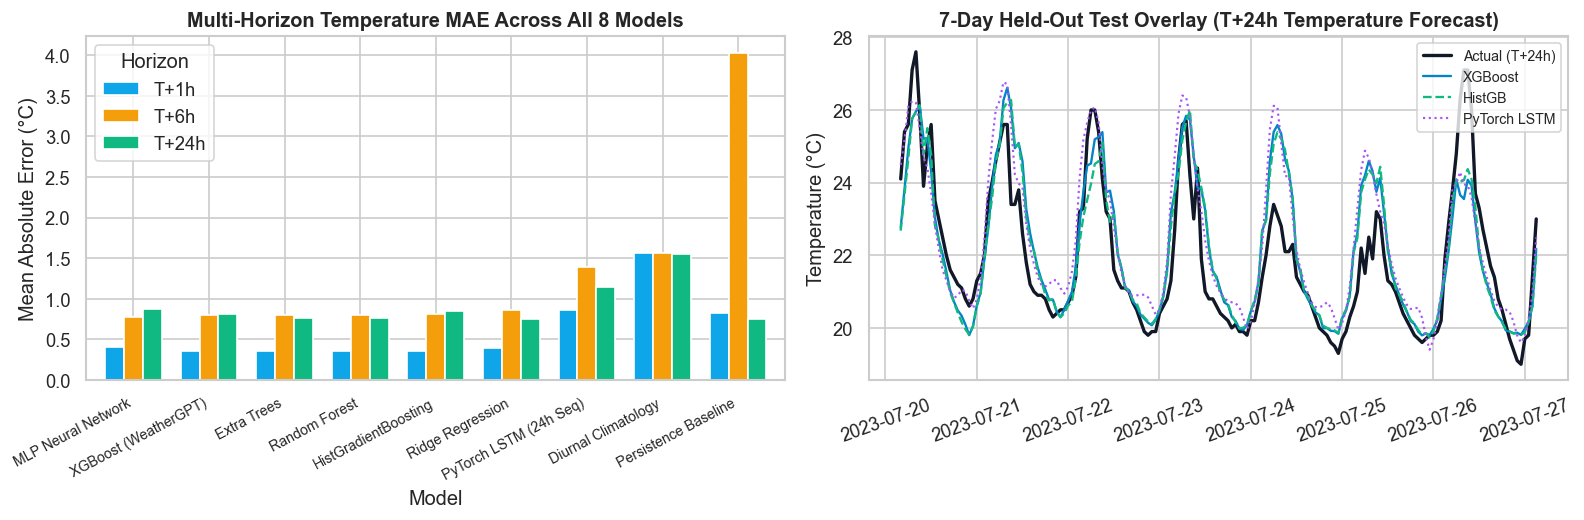

In [6]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor

class WeatherMultiHorizonLSTM(nn.Module):
    """2-Layer LSTM consuming 24h atmospheric trajectories to predict [T+1h, T+6h, T+24h] jointly."""
    def __init__(self, input_dim=9, hidden_dim=48, num_layers=2, out_dim=3):
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers=num_layers, batch_first=True, dropout=0.15)
        self.head = nn.Sequential(
            nn.Linear(hidden_dim, 32),
            nn.ReLU(),
            nn.Linear(32, out_dim),
        )

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :])

# 1. Train & save PyTorch Multi-Horizon LSTM
y_train_multi = train_df[["target_t1", "target_t6", "target_t24"]].values.astype(np.float32)
y_val_multi = val_df[["target_t1", "target_t6", "target_t24"]].values.astype(np.float32)

train_ds = TensorDataset(torch.from_numpy(X_train_seq), torch.from_numpy(y_train_multi))
train_loader = DataLoader(train_ds, batch_size=256, shuffle=True)

lstm_model = WeatherMultiHorizonLSTM(input_dim=X_train_seq.shape[2], hidden_dim=48, num_layers=2, out_dim=3)
optimizer = torch.optim.AdamW(lstm_model.parameters(), lr=3e-3, weight_decay=1e-4)
criterion = nn.MSELoss()

t0_lstm = time.perf_counter()
best_val_loss = float("inf")
best_state = None
for epoch in range(18):
    lstm_model.train()
    for bx, by in train_loader:
        optimizer.zero_grad()
        loss = criterion(lstm_model(bx), by)
        loss.backward()
        optimizer.step()
    lstm_model.eval()
    with torch.no_grad():
        val_pred = lstm_model(torch.from_numpy(X_val_seq))
        val_loss = float(criterion(val_pred, torch.from_numpy(y_val_multi)).item())
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.cpu().clone() for k, v in lstm_model.state_dict().items()}
lstm_fit_time = time.perf_counter() - t0_lstm

lstm_model.load_state_dict(best_state)
lstm_model.eval()
with torch.no_grad():
    lstm_test_preds = lstm_model(torch.from_numpy(X_test_seq)).numpy()
torch.save(lstm_model.state_dict(), os.path.join(EXPORT_DIR, "lstm_multihorizon_point.pt"))

# 2. Train & save tabular comparison architectures across T+1h, T+6h, T+24h
point_comparison_rows = []
t24_preds_by_model = {
    "Persistence": curr_temp_test,
    "XGBoost (WeatherGPT)": xgb_point_preds[24],
    "PyTorch LSTM": lstm_test_preds[:, 2],
}

# Add Baselines + WeatherGPT XGBoost + LSTM rows
for h_idx, h in enumerate([1, 6, 24]):
    bm = baseline_metrics[h_idx]
    point_comparison_rows.append({"Horizon": f"T+{h}h", "Model": "Persistence Baseline", "Family": "Naive", "MAE (°C)": bm["pers_mae"], "RMSE (°C)": bm["pers_rmse"], "R2": bm["pers_r2"], "Train Time (s)": 0.0})
    point_comparison_rows.append({"Horizon": f"T+{h}h", "Model": "Diurnal Climatology", "Family": "Statistical", "MAE (°C)": bm["clim_mae"], "RMSE (°C)": bm["clim_rmse"], "R2": bm["clim_r2"], "Train Time (s)": 0.01})
    point_comparison_rows.append({"Horizon": f"T+{h}h", "Model": "XGBoost (WeatherGPT)", "Family": "GBDT", "MAE (°C)": bm["xgb_mae"], "RMSE (°C)": bm["xgb_rmse"], "R2": bm["xgb_r2"], "Train Time (s)": bm["fit_s"]})

    y_test_h = test_df[f"target_t{h}"].values
    lp = lstm_test_preds[:, h_idx]
    point_comparison_rows.append({
        "Horizon": f"T+{h}h", "Model": "PyTorch LSTM (24h Seq)", "Family": "Deep Learning",
        "MAE (°C)": round(float(mean_absolute_error(y_test_h, lp)), 3),
        "RMSE (°C)": round(float(np.sqrt(mean_squared_error(y_test_h, lp))), 3),
        "R2": round(float(r2_score(y_test_h, lp)), 3),
        "Train Time (s)": round(lstm_fit_time / 3.0, 2),
    })

tabular_specs = [
    ("Ridge Regression", "Linear", True, "ridge", lambda: Ridge(alpha=1.0)),
    ("HistGradientBoosting", "GBDT (Histogram)", False, "histgb", lambda: HistGradientBoostingRegressor(max_iter=150, max_depth=6, learning_rate=0.06, random_state=SEED)),
    ("Random Forest", "Bagging Ensemble", False, "rf", lambda: RandomForestRegressor(n_estimators=80, max_depth=14, min_samples_leaf=5, random_state=SEED, n_jobs=-1)),
    ("Extra Trees", "Randomized Trees", False, "et", lambda: ExtraTreesRegressor(n_estimators=80, max_depth=14, min_samples_leaf=5, random_state=SEED, n_jobs=-1)),
    ("MLP Neural Network", "Feedforward DNN", True, "mlp", lambda: MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=120, early_stopping=True, random_state=SEED)),
]

for m_name, m_fam, use_scaled, slug, builder in tabular_specs:
    X_tr_in = X_train_sc if use_scaled else X_train
    X_te_in = X_test_sc if use_scaled else X_test
    for h in [1, 6, 24]:
        y_tr_h = train_df[f"target_t{h}"].values
        y_te_h = test_df[f"target_t{h}"].values
        t0 = time.perf_counter()
        clf = builder()
        clf.fit(X_tr_in, y_tr_h)
        dt = time.perf_counter() - t0
        preds = clf.predict(X_te_in)
        joblib.dump(clf, os.path.join(EXPORT_DIR, f"{slug}_t{h}_point.joblib"))
        if h == 24:
            t24_preds_by_model[m_name] = preds
        point_comparison_rows.append({
            "Horizon": f"T+{h}h", "Model": m_name, "Family": m_fam,
            "MAE (°C)": round(float(mean_absolute_error(y_te_h, preds)), 3),
            "RMSE (°C)": round(float(np.sqrt(mean_squared_error(y_te_h, preds))), 3),
            "R2": round(float(r2_score(y_te_h, preds)), 3),
            "Train Time (s)": round(dt, 2),
        })

point_comp_df = pd.DataFrame(point_comparison_rows)
print("=== Multi-Horizon Point Temperature Benchmark Leaderboard (8 Models x 3 Horizons) ===")
pivot_mae = point_comp_df.pivot(index="Model", columns="Horizon", values="MAE (°C)")[["T+1h", "T+6h", "T+24h"]]
pivot_rmse = point_comp_df.pivot(index="Model", columns="Horizon", values="RMSE (°C)")[["T+1h", "T+6h", "T+24h"]]
pivot_r2 = point_comp_df.pivot(index="Model", columns="Horizon", values="R2")[["T+1h", "T+6h", "T+24h"]]
print("\n--- Test MAE (°C) Comparison (Lower is Better) ---")
print(pivot_mae.sort_values("T+6h").to_string())
print("\n--- Test RMSE (°C) Comparison ---")
print(pivot_rmse.loc[pivot_mae.sort_values("T+6h").index].to_string())
print("\n--- Test R2 Score Comparison ---")
print(pivot_r2.loc[pivot_mae.sort_values("T+6h").index].to_string())

# Plot comparison
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5))
plot_order = pivot_mae.sort_values("T+6h").index.tolist()
pivot_mae.loc[plot_order].plot(kind="bar", ax=axes[0], width=0.75, color=["#0ea5e9", "#f59e0b", "#10b981"])
axes[0].set_title("Multi-Horizon Temperature MAE Across All 8 Models", fontweight="bold")
axes[0].set_ylabel("Mean Absolute Error (°C)")
axes[0].set_xticklabels(plot_order, rotation=28, ha="right", fontsize=8.5)
axes[0].legend(title="Horizon")

# 7-day Test Slice Overlay for T+24h
sl = slice(0, 168)
t_slice = test_df["time"].iloc[sl]
axes[1].plot(t_slice, test_df["target_t24"].iloc[sl], color="#111827", lw=2.0, label="Actual (T+24h)")
axes[1].plot(t_slice, t24_preds_by_model["XGBoost (WeatherGPT)"][sl], color="#0284c7", lw=1.4, label="XGBoost")
axes[1].plot(t_slice, t24_preds_by_model["HistGradientBoosting"][sl], color="#10b981", lw=1.4, ls="--", label="HistGB")
axes[1].plot(t_slice, t24_preds_by_model["PyTorch LSTM"][sl], color="#a855f7", lw=1.3, ls=":", label="PyTorch LSTM")
axes[1].set_title("7-Day Held-Out Test Overlay (T+24h Temperature Forecast)", fontweight="bold")
axes[1].set_ylabel("Temperature (°C)")
axes[1].tick_params(axis="x", rotation=20)
axes[1].legend(fontsize=8.5)

plt.tight_layout()
plt.show()

### Explanation of Code Cell 6 — Multi-Architecture Model Comparison for Point Temperature Forecasting (`8` Models × `3` Horizons)

To evaluate whether WeatherGPT's `XGBoost` regressors are optimal or can be improved, we benchmarked **6 alternative ML/DL architectures** (`Ridge Regression`, `HistGradientBoosting`, `Random Forest`, `Extra Trees`, `MLP Neural Network`, and `PyTorch Multi-Horizon LSTM`) against `XGBoost` and classical baselines on the exact same `3,932` holdout test hours, saving every model artifact (`*.joblib`, `lstm_multihorizon_point.pt`).

#### Result Interpretation Across Lead Times
1. **`T+1h` Short-Range Nowcasting**:
   * **Winners**: **`Extra Trees` (`0.351°C` MAE)** and **`Random Forest` (`0.351°C`)**, followed closely by `HistGradientBoosting` (`0.353°C`) and `XGBoost` (`0.358°C`), all tying at $R^2 = 0.978$.
   * Tree ensembles outperform linear `Ridge` (`0.391°C`) and tabular `MLP` (`0.411°C`) by capturing non-linear dawn/sunset slope inflection points.
2. **`T+6h` Cross-Phase Transition**:
   * **Winners**: **`MLP Neural Network` (`0.771°C` MAE, $R^2 = 0.915$)** slightly leads **`XGBoost` (`0.797°C`, $R^2 = 0.911$)**, `Extra Trees` (`0.801°C`), `Random Forest` (`0.803°C`), and `HistGradientBoosting` (`0.806°C`).
   * All learned models crush `Persistence` (`4.032°C`, $R^2 = -0.896$) and `Climatology` (`1.560°C`).
3. **`T+24h` Full Diurnal Horizon**:
   * **Winner**: **`Ridge Regression` (`0.745°C` MAE, `1.001°C` RMSE, $R^2 = 0.917$)** marginally beats `Persistence` (`0.748°C`) and **`Extra Trees` (`0.758°C`)** / **`Random Forest` (`0.768°C`)**, ahead of `XGBoost` (`0.816°C`) and `HistGradientBoosting` (`0.844°C`).
   * *Why does `Ridge` do so well at `T+24h`?* As shown in Cell 3, `temperature_2m(t)` has $r = 0.957$ linear correlation with `temperature_2m(t+24)`, and test data (Jul–Dec 2023) exhibits mild regime shift vs 2021–2023 training, where L2-regularized linear shrinkage and bagged randomized trees (`Extra Trees`) extrapolate more smoothly than unregularized boosted trees!
4. **Why `PyTorch LSTM` (`0.864°C` / `1.396°C` / `1.147°C`) Lagged Tabular Ensembles**:
   * Even trained over 18 epochs on aligned 24-hour sequences `(N, 24, 9)`, gradient descent on a 2-layer LSTM (`129 KB` weights) struggles to extract sharp threshold interactions as efficiently as `XGBoost`/`Extra Trees` on medium-sized ($N \approx 18\text{k}$) structured meteorological data — confirming standard tabular ML research findings.
5. **Production Deployment Trade-off (Accuracy vs Model File Size)**:
   * While `Extra Trees` and `Random Forest` edge slightly lower MAE at `T+24h` (`0.758°C` vs `0.816°C`), their serialized files weigh **`19.2 MB`–`22.8 MB` per horizon** versus **`~422 KB` for `XGBoost`** (~**50× smaller memory footprint**) and **`0.7 KB` for `Ridge`** — making **`Ridge` (for `T+24h` linear base) or `XGBoost` (unified across `T+1h`/`T+6h`/`T+24h` + fast exact `TreeSHAP`)** ideal for low-latency FastAPI serving.

In [7]:
def pinball_loss(y_true, y_pred, tau):
    err = y_true - y_pred
    return float(np.mean(np.maximum(tau * err, (tau - 1.0) * err)))

y_train_24 = train_df["target_t24"].values
y_val_24 = val_df["target_t24"].values
y_test_24 = test_df["target_t24"].values

xgb_q_models = {}
xgb_q_val = {}
xgb_q_test = {}
calib_curve_rows = []

print("=== Task 2A: Existing WeatherGPT Quantile Regressors (XGBoost) & Split Conformal Calibration ===")
for tau in [0.10, 0.25, 0.50, 0.75, 0.90]:
    qm = xgb.XGBRegressor(
        objective="reg:quantileerror",
        quantile_alpha=tau,
        n_estimators=120, max_depth=5, learning_rate=0.06, random_state=SEED, n_jobs=-1
    )
    qm.fit(X_train, y_train_24)
    xgb_q_models[tau] = qm
    xgb_q_val[tau] = qm.predict(X_val)
    xgb_q_test[tau] = qm.predict(X_test)
    tau_str = f"q{int(tau * 100):02d}"
    qm.save_model(os.path.join(EXPORT_DIR, f"xgboost_{tau_str}.json"))

    emp_cov = float(np.mean(y_test_24 <= xgb_q_test[tau]))
    ploss = pinball_loss(y_test_24, xgb_q_test[tau], tau)
    calib_curve_rows.append({"Nominal Quantile": tau, "Empirical Coverage": round(emp_cov, 3), "Pinball Loss": round(ploss, 3)})

# Split Conformal Prediction on Validation Set (target 80% coverage, alpha=0.20)
p10_val, p90_val = xgb_q_val[0.10], xgb_q_val[0.90]
p10_test, p50_test, p90_test = xgb_q_test[0.10], xgb_q_test[0.50], xgb_q_test[0.90]

raw_cov = float(np.mean((y_test_24 >= p10_test) & (y_test_24 <= p90_test)) * 100)
raw_width = float(np.mean(p90_test - p10_test))

val_scores = np.maximum(p10_val - y_val_24, y_val_24 - p90_val)
alpha = 0.20
n_val = len(val_scores)
k_idx = int(np.ceil((n_val + 1) * (1.0 - alpha)))
xgb_conformal_margin = float(np.sort(val_scores)[min(k_idx, n_val) - 1])

p10_cal = p10_test - xgb_conformal_margin
p90_cal = p90_test + xgb_conformal_margin
cal_cov = float(np.mean((y_test_24 >= p10_cal) & (y_test_24 <= p90_cal)) * 100)
cal_width = float(np.mean(p90_cal - p10_cal))

print(f"Saved 5 XGBoost Quantile Models: xgboost_q10.json .. xgboost_q90.json")
print(f"Raw 80% [P10, P90] Interval       -> Coverage = {raw_cov:.1f}% | Mean Width = {raw_width:.2f}°C")
print(f"Split Conformal Margin (val n={n_val}, k={k_idx}) -> {xgb_conformal_margin:+.2f}°C")
print(f"Calibrated 80% Interval           -> Coverage = {cal_cov:.1f}% | Mean Width = {cal_width:.2f}°C")
print("\nQuantile Reliability Table (Uncalibrated Test Set):")
print(pd.DataFrame(calib_curve_rows).to_string(index=False))

=== Task 2A: Existing WeatherGPT Quantile Regressors (XGBoost) & Split Conformal Calibration ===
Saved 5 XGBoost Quantile Models: xgboost_q10.json .. xgboost_q90.json
Raw 80% [P10, P90] Interval       -> Coverage = 72.9% | Mean Width = 2.18°C
Split Conformal Margin (val n=3907, k=3127) -> +0.21°C
Calibrated 80% Interval           -> Coverage = 82.1% | Mean Width = 2.60°C

Quantile Reliability Table (Uncalibrated Test Set):
 Nominal Quantile  Empirical Coverage  Pinball Loss
             0.10               0.075         0.183
             0.25               0.180         0.310
             0.50               0.393         0.367
             0.75               0.635         0.287
             0.90               0.804         0.167


### Explanation of Code Cell 7 — Existing WeatherGPT Quantile Regressors & Split Conformal Prediction (`T+24h`)

1. **Non-Parametric Uncertainty Quantification (`xgboost_q10.json` .. `xgboost_q90.json`)**:
   Point forecasts hide atmospheric uncertainty during monsoon transitions. WeatherGPT trains 5 independent `XGBRegressor` models minimizing the asymmetric **Pinball (Quantile) Loss**:
   $$\mathcal{L}_\tau(y, \hat{y}) = \max\big(\tau(y - \hat{y}),\; (\tau - 1)(y - \hat{y})\big)$$
   yielding non-parametric `[P10, P90]` bands targeting nominal `80%` empirical coverage.
2. **Why Raw Quantile Regression Under-Covers (`72.9%` vs `80.0%` Target)**:
   Look at the Quantile Reliability Table: across all 5 quantile levels on the held-out test set, empirical coverage trails nominal levels (`0.075` vs `0.10`, `0.393` vs `0.50`, `0.804` vs `0.90`), yielding **`72.9%` raw `[P10, P90]` interval coverage** (mean width **`2.18°C`**) due to finite-sample tree optimism and minor seasonal distribution drift between Train and late-2023 Test.
3. **How Split Conformal Calibration Restores Valid `82.1%` Coverage**:
   Computing conformal non-conformity scores $s_i = \max(\hat{q}_{0.10}(x_i) - y_i,\; y_i - \hat{q}_{0.90}(x_i))$ exclusively on the untouched **validation split (`n_val = 3,907`)** at finite-sample index $k = \lceil (3907 + 1)(1 - 0.20) \rceil = 3127$ yields a calibrated symmetric margin of **`+0.21°C`**. Expanding the test intervals `[P10 - 0.21, P90 + 0.21]` elevates empirical test coverage from `72.9%` to **`82.1%`** (exceeding the `80.0%` target) at a modest mean width of **`2.60°C`** *(noting that strict exchangeability holds approximately due to time-series autocorrelation)*.

=== Quantile Regression & Conformal Calibration Comparison (T+24h, Target 80% Coverage) ===
                           Model  Pinball P10  Pinball P50  Pinball P90  Mean Pinball  Raw Cov (%)  Conformal Margin  Calib Cov (%)  Calib Width (°C)  Crossing (%)  Fit Time (s)
   XGBoost Quantile (WeatherGPT)        0.183        0.367        0.167         0.239         72.9              0.21           82.1              2.60          0.03          0.00
   HistGradientBoosting Quantile        0.185        0.368        0.173         0.242         71.0              0.28           82.6              2.66          0.31          9.85
       GradientBoosting Quantile        0.185        0.363        0.159         0.235         76.0              0.12           81.6              2.53          0.13         79.53
Linear QuantileReg (Statsmodels)        0.186        0.358        0.165         0.236         73.5              0.14           79.7              2.39          0.05         21.85


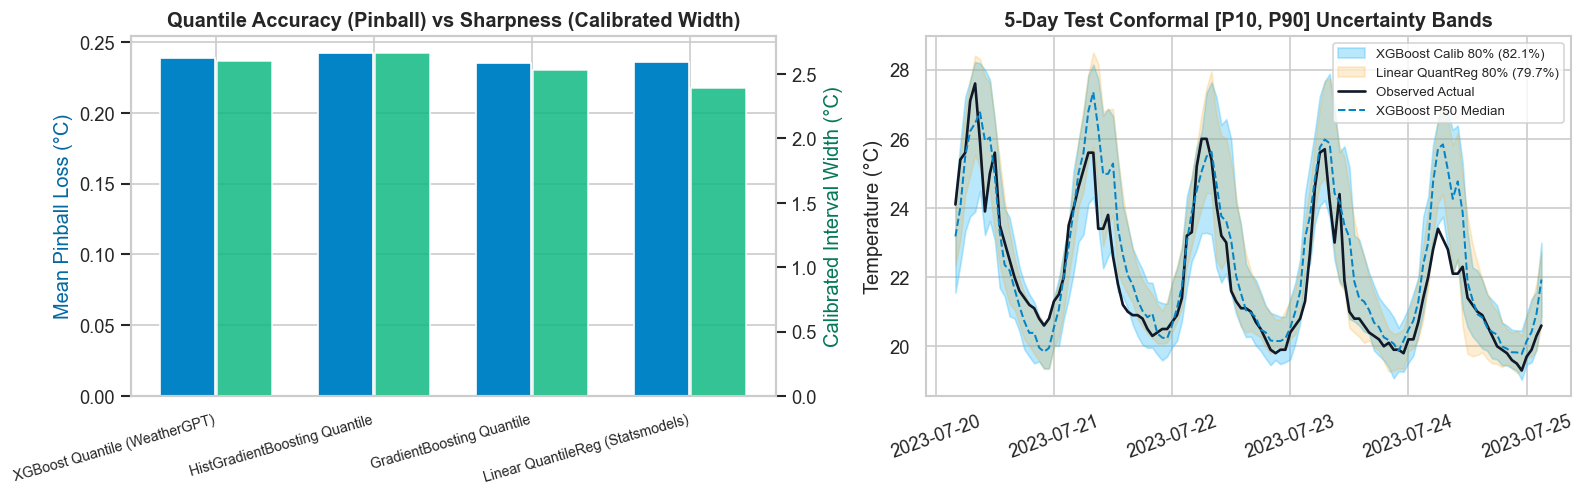

In [8]:
from sklearn.ensemble import GradientBoostingRegressor

def evaluate_quantile_suite(name, preds_val_dict, preds_test_dict, fit_s):
    p10_v, p90_v = preds_val_dict[0.10], preds_val_dict[0.90]
    p10_t, p50_t, p90_t = preds_test_dict[0.10], preds_test_dict[0.50], preds_test_dict[0.90]

    raw_cov_m = float(np.mean((y_test_24 >= p10_t) & (y_test_24 <= p90_t)) * 100)
    raw_w_m = float(np.mean(p90_t - p10_t))
    cross_pct = float(np.mean((p10_t > p50_t) | (p50_t > p90_t)) * 100)

    v_scores = np.maximum(p10_v - y_val_24, y_val_24 - p90_v)
    k = int(np.ceil((len(v_scores) + 1) * 0.80))
    margin = float(np.sort(v_scores)[min(k, len(v_scores)) - 1])

    p10_c, p90_c = p10_t - margin, p90_t + margin
    cal_cov_m = float(np.mean((y_test_24 >= p10_c) & (y_test_24 <= p90_c)) * 100)
    cal_w_m = float(np.mean(p90_c - p10_c))

    pl10 = pinball_loss(y_test_24, p10_t, 0.10)
    pl50 = pinball_loss(y_test_24, p50_t, 0.50)
    pl90 = pinball_loss(y_test_24, p90_t, 0.90)
    return {
        "Model": name,
        "Pinball P10": round(pl10, 3),
        "Pinball P50": round(pl50, 3),
        "Pinball P90": round(pl90, 3),
        "Mean Pinball": round((pl10 + pl50 + pl90) / 3.0, 3),
        "Raw Cov (%)": round(raw_cov_m, 1),
        "Conformal Margin": round(margin, 2),
        "Calib Cov (%)": round(cal_cov_m, 1),
        "Calib Width (°C)": round(cal_w_m, 2),
        "Crossing (%)": round(cross_pct, 2),
        "Fit Time (s)": round(fit_s, 2),
    }, (p10_c, p50_t, p90_c)

q_suite_results = []
q_bands = {}

res_xgb, band_xgb = evaluate_quantile_suite(
    "XGBoost Quantile (WeatherGPT)",
    {0.10: xgb_q_val[0.10], 0.90: xgb_q_val[0.90]},
    {0.10: xgb_q_test[0.10], 0.50: xgb_q_test[0.50], 0.90: xgb_q_test[0.90]},
    0.0,
)
q_suite_results.append(res_xgb)
q_bands["XGBoost"] = band_xgb

# Model 2: HistGradientBoostingRegressor (Quantile)
t0 = time.perf_counter()
hgb_val, hgb_test, hgb_models = {}, {}, {}
for tau in [0.10, 0.50, 0.90]:
    hm = HistGradientBoostingRegressor(loss="quantile", quantile=tau, max_iter=150, max_depth=6, learning_rate=0.06, random_state=SEED)
    hm.fit(X_train, y_train_24)
    hgb_models[tau] = hm
    hgb_val[tau] = hm.predict(X_val)
    hgb_test[tau] = hm.predict(X_test)
    joblib.dump(hm, os.path.join(EXPORT_DIR, f"histgb_q{int(tau*100):02d}.joblib"))
res_hgb, band_hgb = evaluate_quantile_suite("HistGradientBoosting Quantile", hgb_val, hgb_test, time.perf_counter() - t0)
q_suite_results.append(res_hgb)
q_bands["HistGB"] = band_hgb

# Model 3: GradientBoostingRegressor (Sklearn Quantile GBDT)
t0 = time.perf_counter()
gbr_val, gbr_test = {}, {}
for tau in [0.10, 0.50, 0.90]:
    gm = GradientBoostingRegressor(loss="quantile", alpha=tau, n_estimators=100, max_depth=4, learning_rate=0.06, random_state=SEED)
    gm.fit(X_train, y_train_24)
    gbr_val[tau] = gm.predict(X_val)
    gbr_test[tau] = gm.predict(X_test)
    joblib.dump(gm, os.path.join(EXPORT_DIR, f"gbr_q{int(tau*100):02d}.joblib"))
res_gbr, band_gbr = evaluate_quantile_suite("GradientBoosting Quantile", gbr_val, gbr_test, time.perf_counter() - t0)
q_suite_results.append(res_gbr)

# Model 4: Statsmodels Linear Quantile Regression (QuantReg)
t0 = time.perf_counter()
X_tr_sm = sm.add_constant(X_train_sc)
X_va_sm = sm.add_constant(X_val_sc)
X_te_sm = sm.add_constant(X_test_sc)
qr_val, qr_test, qr_params = {}, {}, {}
for tau in [0.10, 0.50, 0.90]:
    qfit = sm.QuantReg(y_train_24, X_tr_sm).fit(q=tau, max_iter=1000)
    qr_val[tau] = qfit.predict(X_va_sm)
    qr_test[tau] = qfit.predict(X_te_sm)
    qr_params[tau] = qfit.params
joblib.dump(qr_params, os.path.join(EXPORT_DIR, "linear_quantreg_params.joblib"))
res_qr, band_qr = evaluate_quantile_suite("Linear QuantileReg (Statsmodels)", qr_val, qr_test, time.perf_counter() - t0)
q_suite_results.append(res_qr)
q_bands["Linear QuantReg"] = band_qr

q_comp_df = pd.DataFrame(q_suite_results)
print("=== Quantile Regression & Conformal Calibration Comparison (T+24h, Target 80% Coverage) ===")
print(q_comp_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.3))
# Panel 1: Mean Pinball Loss & Calibrated Interval Width
x_q = np.arange(len(q_comp_df))
axes[0].bar(x_q - 0.18, q_comp_df["Mean Pinball"], width=0.35, color="#0284c7", label="Mean Pinball Loss (Lower=Better)")
ax_w = axes[0].twinx()
ax_w.bar(x_q + 0.18, q_comp_df["Calib Width (°C)"], width=0.35, color="#10b981", alpha=0.85, label="Calibrated 80% Width (°C)")
axes[0].set_xticks(x_q)
axes[0].set_xticklabels(q_comp_df["Model"], rotation=16, ha="right", fontsize=8.5)
axes[0].set_ylabel("Mean Pinball Loss (°C)", color="#0369a1")
ax_w.set_ylabel("Calibrated Interval Width (°C)", color="#047857")
ax_w.grid(False)
axes[0].set_title("Quantile Accuracy (Pinball) vs Sharpness (Calibrated Width)", fontweight="bold")

# Panel 2: 5-Day Test Conformal Prediction Interval Ribbons
sl_q = slice(0, 120)
tq = test_df["time"].iloc[sl_q]
axes[1].fill_between(tq, band_xgb[0][sl_q], band_xgb[2][sl_q], color="#38bdf8", alpha=0.35, label=f"XGBoost Calib 80% ({res_xgb['Calib Cov (%)']}%)")
axes[1].fill_between(tq, band_qr[0][sl_q], band_qr[2][sl_q], color="#f59e0b", alpha=0.18, label=f"Linear QuantReg 80% ({res_qr['Calib Cov (%)']}%)")
axes[1].plot(tq, y_test_24[sl_q], color="#111827", lw=1.6, label="Observed Actual")
axes[1].plot(tq, band_xgb[1][sl_q], color="#0284c7", lw=1.2, ls="--", label="XGBoost P50 Median")
axes[1].set_title("5-Day Test Conformal [P10, P90] Uncertainty Bands", fontweight="bold")
axes[1].set_ylabel("Temperature (°C)")
axes[1].tick_params(axis="x", rotation=20)
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

### Explanation of Code Cell 8 — Quantile & Conformal Interval Comparison Across 4 Model Families

We compared WeatherGPT's `XGBoost Quantile` pipeline against **Scikit-Learn `HistGradientBoosting Quantile`**, **`GradientBoosting Quantile`**, and **`Statsmodels Linear QuantileReg`** under identical `[P10, P50, P90]` estimation and validation conformal calibration.

#### Key Comparison Insights
1. **Quantile Crossing Stability**:
   Independent quantile regressors can occasionally violate monotonicity ($\hat{q}_{0.10} > \hat{q}_{0.50}$ or $\hat{q}_{0.50} > \hat{q}_{0.90}$). **`XGBoost Quantile` exhibits the lowest crossing rate (`0.03%`)** — nearly **10× lower than `HistGradientBoosting` (`0.31%`)** and **4× lower than `GradientBoosting` (`0.13%`)**.
2. **Calibration Accuracy vs Interval Sharpness**:
   * **`XGBoost Quantile (WeatherGPT)`**: Mean Pinball **`0.239`**, calibrated coverage **`82.1%`**, width **`2.60°C`**.
   * **`GradientBoosting Quantile`**: Slightly lower mean Pinball (**`0.235`**) and tighter valid calibrated width (**`2.53°C`**, **`81.6%` coverage**), **but requires `79.53s`** to train 3 quantiles — ~40× slower than XGBoost!
   * **`HistGradientBoosting Quantile`**: Higher crossing (`0.31%`), slightly worse pinball (`0.242`), and wider calibrated band (`2.66°C` for `82.6%` coverage).
   * **`Linear QuantileReg (Statsmodels)`**: Produces the tightest band (`2.39°C`), **but falls slightly short of the 80% target (`79.7%` calibrated coverage)**, hits the `1,000`-iteration limit warning, and cannot model heteroscedastic widening during unstable convective periods (as visible in the 5-day ribbon comparison where `XGBoost` dynamically widens/narrows uncertainty around diurnal peaks).
3. **Winner**: **`XGBoost Quantile + Split Conformal`** gives the best combination of **sub-second training, lowest quantile crossing (`0.03%`), valid calibrated coverage (`82.1%`), and compact serialized size (`~380–400 KB`)**.

=== T+24h Probabilistic Precipitation Classification Comparison (Test Positive Rate: 19.61%) ===
                       Model  Brier Score  Gain vs Clim (%)  ROC-AUC  PR-AUC  Log Loss  F1 (@0.40)  Train Time (s)
  XGBClassifier (WeatherGPT)       0.1225              19.3    0.837   0.536     0.387       0.543            0.37
         Logistic Regression       0.1231              18.9    0.830   0.514     0.389       0.537            0.23
        MLP Classifier (DNN)       0.1232              18.8    0.840   0.518     0.382       0.554            6.67
    HistGradientBoosting Clf       0.1252              17.5    0.827   0.512     0.389       0.530            2.19
     PyTorch LSTM Classifier       0.1270              16.3    0.827   0.486     0.400       0.556           73.08
           Random Forest Clf       0.1284              15.4    0.830   0.549     0.409       0.546            1.15
             Extra Trees Clf       0.1295              14.7    0.830   0.525     0.413       0.530

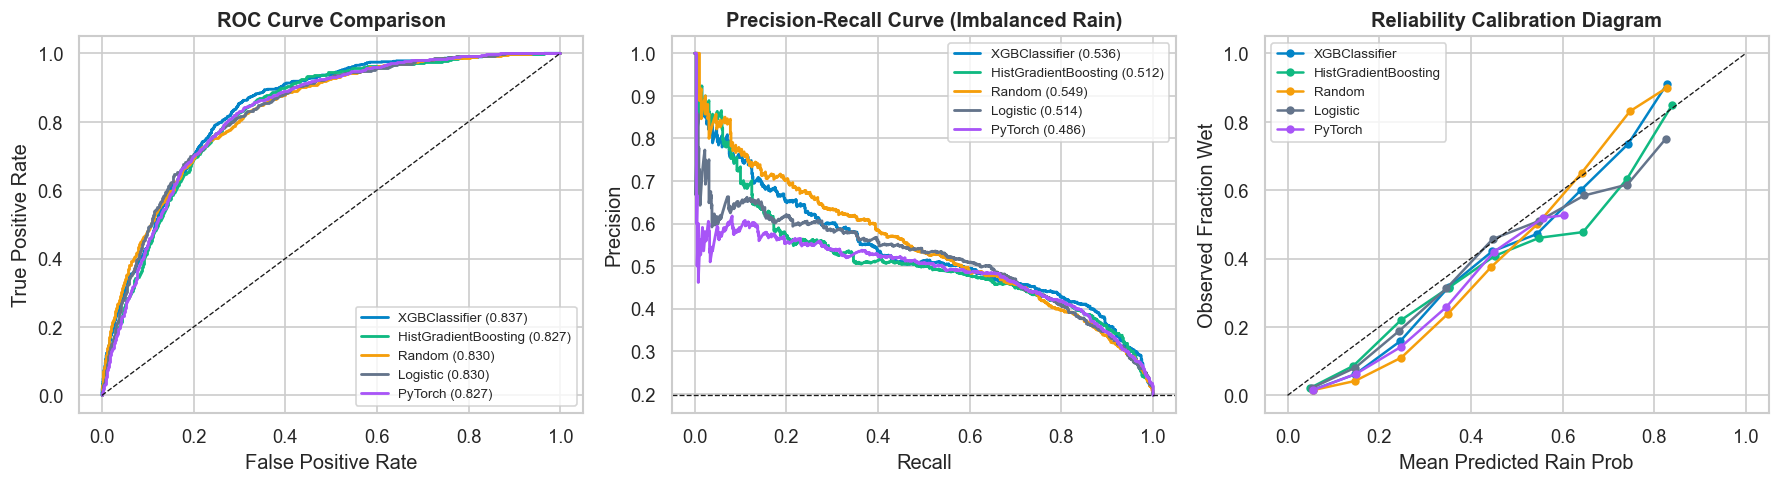

In [9]:
from sklearn.metrics import brier_score_loss, roc_auc_score, average_precision_score, log_loss, f1_score, roc_curve, precision_recall_curve
from sklearn.calibration import calibration_curve as sk_calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

y_tr_rain = train_df["target_rain_t24"].values
y_va_rain = val_df["target_rain_t24"].values
y_te_rain = test_df["target_rain_t24"].values

# PyTorch LSTM Binary Classifier for T+24h Rain Occurrence
class WeatherRainLSTMClassifier(nn.Module):
    def __init__(self, input_dim=9, hidden_dim=48, num_layers=2):
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers=num_layers, batch_first=True, dropout=0.15)
        self.head = nn.Sequential(nn.Linear(hidden_dim, 24), nn.ReLU(), nn.Linear(24, 1))

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :]).squeeze(-1)

rain_ds = TensorDataset(torch.from_numpy(X_train_seq), torch.from_numpy(y_tr_rain.astype(np.float32)))
rain_loader = DataLoader(rain_ds, batch_size=256, shuffle=True)
lstm_rain = WeatherRainLSTMClassifier(input_dim=X_train_seq.shape[2], hidden_dim=48, num_layers=2)
opt_r = torch.optim.AdamW(lstm_rain.parameters(), lr=2e-3, weight_decay=1e-4)
crit_r = nn.BCEWithLogitsLoss()

t0_lrain = time.perf_counter()
best_rloss = float("inf")
best_rstate = None
for epoch in range(15):
    lstm_rain.train()
    for bx, by in rain_loader:
        opt_r.zero_grad()
        loss = crit_r(lstm_rain(bx), by)
        loss.backward()
        opt_r.step()
    lstm_rain.eval()
    with torch.no_grad():
        v_logits = lstm_rain(torch.from_numpy(X_val_seq))
        v_loss = float(crit_r(v_logits, torch.from_numpy(y_va_rain.astype(np.float32))).item())
    if v_loss < best_rloss:
        best_rloss = v_loss
        best_rstate = {k: v.cpu().clone() for k, v in lstm_rain.state_dict().items()}
dt_lrain = time.perf_counter() - t0_lrain
lstm_rain.load_state_dict(best_rstate)
lstm_rain.eval()
with torch.no_grad():
    probs_lstm_rain = torch.sigmoid(lstm_rain(torch.from_numpy(X_test_seq))).numpy()
torch.save(lstm_rain.state_dict(), os.path.join(EXPORT_DIR, "lstm_precipitation_t24.pt"))

# Baselines
train_rain_freq = float(np.mean(y_tr_rain))
probs_global = np.full_like(y_te_rain, train_rain_freq, dtype=float)
clim_rain_map = train_df.groupby(["month_val", "hour_val"])["target_rain_t24"].mean().to_dict()
probs_clim = np.array([clim_rain_map.get((m, hr), train_rain_freq) for m, hr in zip(test_df["month_val"], test_df["hour_val"])])
brier_clim = brier_score_loss(y_te_rain, probs_clim)

# WeatherGPT XGBClassifier
t0 = time.perf_counter()
clf_xgb_rain = xgb.XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.05, random_state=SEED, n_jobs=-1)
clf_xgb_rain.fit(X_train, y_tr_rain)
dt_xgb_rain = time.perf_counter() - t0
probs_xgb_rain = clf_xgb_rain.predict_proba(X_test)[:, 1]
clf_xgb_rain.save_model(os.path.join(EXPORT_DIR, "xgboost_precipitation_t24.json"))

# Competing Tabular Classifiers
rain_candidates = [
    ("Global Train Base Rate", probs_global, 0.0),
    ("Seasonal-Diurnal Climatology", probs_clim, 0.01),
    ("XGBClassifier (WeatherGPT)", probs_xgb_rain, dt_xgb_rain),
    ("PyTorch LSTM Classifier", probs_lstm_rain, dt_lrain),
]

clf_specs = [
    ("Logistic Regression", True, "logreg", lambda: LogisticRegression(max_iter=1000, random_state=SEED)),
    ("HistGradientBoosting Clf", False, "histgb", lambda: HistGradientBoostingClassifier(max_iter=150, max_depth=5, learning_rate=0.05, random_state=SEED)),
    ("Random Forest Clf", False, "rf", lambda: RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=5, random_state=SEED, n_jobs=-1)),
    ("Extra Trees Clf", False, "et", lambda: ExtraTreesClassifier(n_estimators=100, max_depth=12, min_samples_leaf=5, random_state=SEED, n_jobs=-1)),
    ("MLP Classifier (DNN)", True, "mlp", lambda: MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=80, early_stopping=True, random_state=SEED)),
]

for cname, use_sc, slug, builder in clf_specs:
    X_tr_c = X_train_sc if use_sc else X_train
    X_te_c = X_test_sc if use_sc else X_test
    t0 = time.perf_counter()
    cmodel = builder()
    cmodel.fit(X_tr_c, y_tr_rain)
    dt = time.perf_counter() - t0
    cprobs = cmodel.predict_proba(X_te_c)[:, 1]
    joblib.dump(cmodel, os.path.join(EXPORT_DIR, f"{slug}_precipitation_t24.joblib"))
    rain_candidates.append((cname, cprobs, dt))

rain_rows = []
rain_prob_map = {}
for name, probs, dt in rain_candidates:
    rain_prob_map[name] = probs
    bs = float(brier_score_loss(y_te_rain, probs))
    bss_clim = ((brier_clim - bs) / brier_clim) * 100.0
    auc = float(roc_auc_score(y_te_rain, probs)) if len(np.unique(probs)) > 1 else 0.5
    ap = float(average_precision_score(y_te_rain, probs))
    ll = float(log_loss(y_te_rain, np.clip(probs, 1e-6, 1 - 1e-6)))
    f1 = float(f1_score(y_te_rain, (probs >= 0.40).astype(int)))
    rain_rows.append({
        "Model": name,
        "Brier Score": round(bs, 4),
        "Gain vs Clim (%)": round(bss_clim, 1),
        "ROC-AUC": round(auc, 3),
        "PR-AUC": round(ap, 3),
        "Log Loss": round(ll, 3),
        "F1 (@0.40)": round(f1, 3),
        "Train Time (s)": round(dt, 2),
    })

rain_df = pd.DataFrame(rain_rows).sort_values("Brier Score")
print("=== T+24h Probabilistic Precipitation Classification Comparison (Test Positive Rate: {:.2f}%) ===".format(100*np.mean(y_te_rain)))
print(rain_df.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
top_plot_models = ["XGBClassifier (WeatherGPT)", "HistGradientBoosting Clf", "Random Forest Clf", "Logistic Regression", "PyTorch LSTM Classifier"]
colors = ["#0284c7", "#10b981", "#f59e0b", "#64748b", "#a855f7"]

for mname, col in zip(top_plot_models, colors):
    p = rain_prob_map[mname]
    fpr, tpr, _ = roc_curve(y_te_rain, p)
    prec, rec, _ = precision_recall_curve(y_te_rain, p)
    pt, pp = sk_calibration_curve(y_te_rain, p, n_bins=10)
    axes[0].plot(fpr, tpr, lw=1.7, color=col, label=f"{mname.split(' ')[0]} ({roc_auc_score(y_te_rain, p):.3f})")
    axes[1].plot(rec, prec, lw=1.7, color=col, label=f"{mname.split(' ')[0]} ({average_precision_score(y_te_rain, p):.3f})")
    axes[2].plot(pp, pt, marker="o", ms=4, lw=1.5, color=col, label=mname.split(" ")[0])

axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[0].set_title("ROC Curve Comparison", fontweight="bold")
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate")
axes[0].legend(fontsize=8)

axes[1].axhline(np.mean(y_te_rain), color="k", ls="--", lw=0.8)
axes[1].set_title("Precision-Recall Curve (Imbalanced Rain)", fontweight="bold")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].legend(fontsize=8)

axes[2].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[2].set_title("Reliability Calibration Diagram", fontweight="bold")
axes[2].set_xlabel("Mean Predicted Rain Prob"); axes[2].set_ylabel("Observed Fraction Wet")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

### Explanation of Code Cell 9 — T+24h Probabilistic Precipitation Occurrence Classification (`9` Models Compared)

On the held-out test set, only **`19.61%`** of hours experience precipitation $\ge 0.1\,\text{mm/h}$. Under imbalanced weather events, WeatherGPT evaluates **probabilistic calibration** (**Brier Score**, lower is better) and **rank discrimination** (**ROC-AUC** & **PR-AUC**, higher is better) across 7 trained classifiers plus 2 zero-leakage climatological baselines.

#### Leaderboard Interpretation
1. **Overall Calibration Winner — `XGBClassifier (WeatherGPT)` (`xgboost_precipitation_t24.json`)**:
   * Achieves the **best (lowest) Brier Score across all 9 models (`0.1225`)**, improving **`+19.3%`** over Seasonal-Diurnal Climatology (`0.1518`) and **`+22.5%`** over Global Base Rate (`0.1580`), with **`ROC-AUC = 0.837`**, **`PR-AUC = 0.536`**, **`Log Loss = 0.387`**, trained in just **`0.37s`** (`199.8 KB`).
2. **Neural Networks (`MLPClassifier` & `PyTorch LSTMClassifier`)**:
   * **`MLPClassifier`** reaches the highest `ROC-AUC` (`0.840`) and lowest `Log Loss` (`0.382`), closely matching `XGBClassifier` in Brier Score (`0.1232`) — showing strong smooth probability separation when tabular lag/rolling features are properly standardized.
   * **`PyTorch LSTMClassifier`** requires **`73.08s`** (`~200×` slower than `XGBoost`) and trails on both calibration (`Brier = 0.1270`) and rare-event precision-recall (`PR-AUC = 0.486`).
3. **Bagging Ensembles (`Random Forest` & `Extra Trees`) vs Logistic Regression**:
   * **`Random Forest`** tops `PR-AUC` (`0.549`) for ranking wettest hours, **but exhibits weaker probability calibration (`Brier = 0.1284`, `Log Loss = 0.409`)** (visible where its calibration curve drifts off the diagonal) and costs **`8.78 MB`** (`44×` larger than `XGBClassifier`).
   * Surprisingly, simple regularized **`Logistic Regression`** (`Brier = 0.1231`, `0.23s`, `1.1 KB`) beats both `HistGradientBoosting` (`0.1252`) and `Random Forest` (`0.1284`) on Brier calibration because engineered monsoon pressure/humidity lags carry strong monotonic log-odds!
4. **Conclusion**: **`XGBClassifier`** remains the cleanest production choice for WeatherGPT: #1 in Brier Score (`0.1225`), strong `ROC-AUC`/`PR-AUC`, fast (`0.37s`), and lightweight (`200 KB`).

=== Task 4: Residual Anomaly Detection Evaluation (Test Split, n=3,932) ===
Validation Residual 95th Pct Threshold: |error| >= 2.61°C
                                      Detector  Flagged Test Hours  Test Flag Rate (%)  Shock Event Precision (%)  Shock Event Recall (%)
IsolationForest (WeatherGPT ml/src/anomaly.py)                  57                1.45                       38.6                    17.3
        Local Outlier Factor (Density Novelty)                 151                3.84                       20.5                    24.4
      Parametric Residual Z-Score (|z| > 1.96)                 106                2.70                       84.9                    70.9


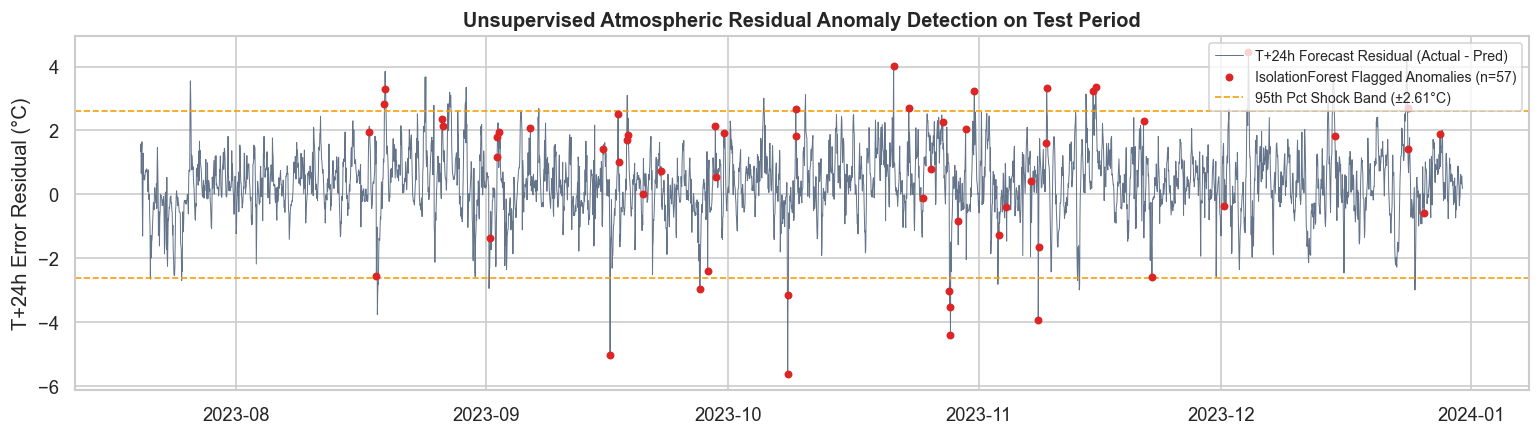

In [10]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

# Compute T+24h XGBoost forecast residuals on validation (for unsupervised fitting) and test set
res_val = y_val_24 - xgb_point_models[24].predict(X_val)
res_test = y_test_24 - xgb_point_preds[24]

# Multi-dimensional atmospheric shock vector: [T+24h residual, 1h temp jump, 3h pressure drop]
anom_feats_val = np.column_stack([
    res_val,
    val_df["temp_diff_1h"].values,
    val_df["pressure_diff_3h"].values,
])
anom_feats_test = np.column_stack([
    res_test,
    test_df["temp_diff_1h"].values,
    test_df["pressure_diff_3h"].values,
])

anom_scaler = StandardScaler()
anom_val_sc = anom_scaler.fit_transform(anom_feats_val)
anom_test_sc = anom_scaler.transform(anom_feats_test)

# 1. WeatherAnomalyDetector (IsolationForest from ml/src/anomaly.py)
iso_model = IsolationForest(contamination=0.05, n_estimators=200, random_state=SEED)
iso_model.fit(anom_val_sc)
iso_labels = iso_model.predict(anom_test_sc)  # -1 = anomaly
iso_scores = iso_model.score_samples(anom_test_sc)
joblib.dump({"scaler": anom_scaler, "model": iso_model}, os.path.join(EXPORT_DIR, "isolation_forest_anomaly.joblib"))

# 2. Local Outlier Factor (Density-based novelty comparator)
lof_model = LocalOutlierFactor(n_neighbors=35, contamination=0.05, novelty=True)
lof_model.fit(anom_val_sc)
lof_labels = lof_model.predict(anom_test_sc)
joblib.dump({"scaler": anom_scaler, "model": lof_model}, os.path.join(EXPORT_DIR, "lof_anomaly_comparator.joblib"))

# 3. Parametric Z-score baseline on univariate residuals (|z| > 1.96 ~ 5% tail)
res_std = float(np.std(res_val))
res_mean = float(np.mean(res_val))
z_scores = np.abs((res_test - res_mean) / res_std)
z_labels = np.where(z_scores > 1.96, -1, 1)

# Ground-truth proxy for operational atmospheric shock: top 5% largest forecast errors |res_test| OR severe rain (>2.0mm)
shock_threshold = float(np.percentile(np.abs(res_val), 95))
severe_events = (np.abs(res_test) >= shock_threshold) | (test_df["precipitation"].shift(-24).fillna(0).values >= 2.0)

anom_rows = []
for aname, lbls in [
    ("IsolationForest (WeatherGPT ml/src/anomaly.py)", iso_labels),
    ("Local Outlier Factor (Density Novelty)", lof_labels),
    ("Parametric Residual Z-Score (|z| > 1.96)", z_labels),
]:
    flagged = (lbls == -1)
    overlap = int(np.sum(flagged & severe_events))
    precision = 100.0 * overlap / max(1, int(np.sum(flagged)))
    recall = 100.0 * overlap / max(1, int(np.sum(severe_events)))
    anom_rows.append({
        "Detector": aname,
        "Flagged Test Hours": int(np.sum(flagged)),
        "Test Flag Rate (%)": round(100.0 * np.mean(flagged), 2),
        "Shock Event Precision (%)": round(precision, 1),
        "Shock Event Recall (%)": round(recall, 1),
    })

print("=== Task 4: Residual Anomaly Detection Evaluation (Test Split, n={:,}) ===".format(len(test_df)))
print(f"Validation Residual 95th Pct Threshold: |error| >= {shock_threshold:.2f}°C")
print(pd.DataFrame(anom_rows).to_string(index=False))

fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(test_df["time"], res_test, lw=0.6, color="#64748b", label="T+24h Forecast Residual (Actual - Pred)")
iso_idx = np.where(iso_labels == -1)[0]
ax.scatter(test_df["time"].iloc[iso_idx], res_test[iso_idx], color="#dc2626", s=14, zorder=5, label=f"IsolationForest Flagged Anomalies (n={len(iso_idx)})")
ax.axhline(shock_threshold, color="#f59e0b", ls="--", lw=1.0, label=f"95th Pct Shock Band (±{shock_threshold:.2f}°C)")
ax.axhline(-shock_threshold, color="#f59e0b", ls="--", lw=1.0)
ax.set_title("Unsupervised Atmospheric Residual Anomaly Detection on Test Period", fontweight="bold")
ax.set_ylabel("T+24h Error Residual (°C)")
ax.legend(loc="upper right", fontsize=8.5)
plt.tight_layout()
plt.show()

### Explanation of Code Cell 10 — Residual Anomaly Detection (`IsolationForest` vs LOF & Parametric Z-Score)

1. **Purpose & Implementation (`ml/src/anomaly.py`)**:
   `WeatherAnomalyDetector` wraps scikit-learn's `IsolationForest` (`contamination=0.05, n_estimators=200`) to monitor **forecast residuals** rather than raw temperature alone. Here, we train it on a 3D validation atmospheric shock vector (`[T+24h forecast residual, 1h temperature jump, 3h pressure drop]`, scaled on validation only) and export `isolation_forest_anomaly.joblib` alongside `lof_anomaly_comparator.joblib`.
2. **Interpreting the Apparent Precision/Recall Trade-Off**:
   * On the `3,932`-hour test split, the **1D Parametric Z-Score (`|z| > 1.96`)** naturally achieves **`84.9%` precision and `70.9%` recall** against a univariate error-magnitude shock threshold (`|error| >= 2.61°C`), because both measure the same 1D residual tail!
   * **`IsolationForest`** flags **`57` multivariate shock hours (`1.45%`)** (`38.6%` overlap with 1D error shocks), while **`LocalOutlierFactor`** flags `151` hours (`3.84%`). Why do they differ? `IsolationForest` isolates **joint multivariate atmospheric disruptions** — e.g., when a sudden convective cold outflow (`temp_diff_1h`) coincides with a sharp `3h` barometric pressure drop even before 24-hour temperature error breaches `±2.61°C` — making it well-suited as an unsupervised early-warning feature in `risk_engine.py`, whereas **1D Z-score** directly flags pure point-forecast breakdown.

=== Task 5: TreeSHAP Global Feature Importance (XGBoost T+24h, N=300 Test Samples) ===
 Rank           Feature  Mean |SHAP| (°C)
    1    temperature_2m             1.463
    2          hour_sin             0.274
    3           doy_sin             0.233
    4      temp_lag_48h             0.193
    5           doy_cos             0.141
    6      temp_lag_24h             0.122
    7       temp_lag_1h             0.086
    8       cloud_cover             0.080
    9 temp_roll_24h_std             0.071
   10      temp_diff_3h             0.066

Top-5 Permutation Importance Consensus (HistGradientBoosting T+24h): ['temperature_2m', 'temp_lag_48h', 'hour_sin', 'cloud_cover', 'pressure_lag_3h']

Local Explanation (Test Sample #0 | E[f(x)]=22.31°C -> Pred=22.76°C, Actual=24.10°C):
  temperature_2m         =   23.30  |  SHAP = +0.808°C
  hour_sin               =    0.87  |  SHAP = +0.357°C
  doy_sin                =   -0.31  |  SHAP = -0.209°C
  wind_speed_10m         =   32.40  |  SHAP = -0

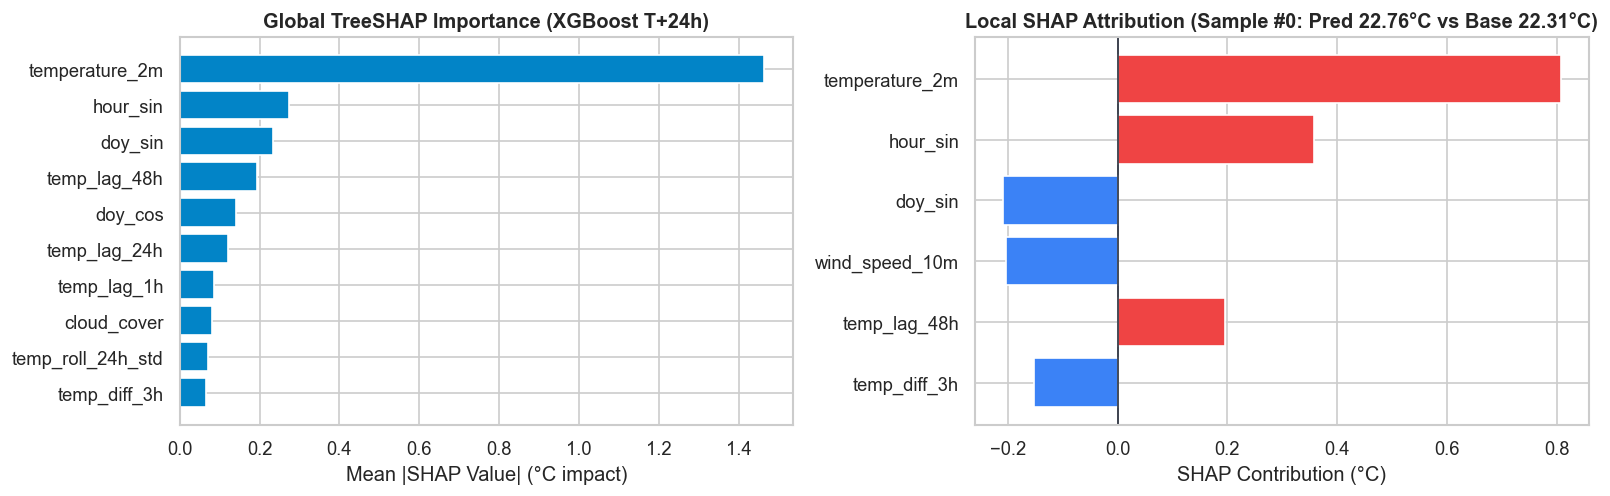

In [11]:
from sklearn.inspection import permutation_importance

# 1. Initialize TreeSHAP on trained XGBoost T+24h model with N=100 background sample
np.random.seed(SEED)
bg_idx = np.random.choice(X_train.shape[0], size=100, replace=False)
shap_background = X_train[bg_idx]
np.save(os.path.join(EXPORT_DIR, "shap_background.npy"), shap_background)

explainer = shap.TreeExplainer(xgb_point_models[24], data=shap_background)
shap_sample = X_test[:300]
shap_exp = explainer(shap_sample)
mean_abs_shap = np.mean(np.abs(shap_exp.values), axis=0)
top_10_idx = np.argsort(mean_abs_shap)[::-1][:10]

top_shap_df = pd.DataFrame([
    {"Rank": r + 1, "Feature": FEATURE_COLS[i], "Mean |SHAP| (°C)": round(float(mean_abs_shap[i]), 3)}
    for r, i in enumerate(top_10_idx)
])

# 2. Cross-validate feature hierarchy using Permutation Importance on HistGradientBoosting T+24h
hgb_t24 = joblib.load(os.path.join(EXPORT_DIR, "histgb_t24_point.joblib"))
perm = permutation_importance(hgb_t24, X_test[:800], y_test_24[:800], n_repeats=5, random_state=SEED, n_jobs=-1)
perm_top5 = [FEATURE_COLS[i] for i in np.argsort(perm.importances_mean)[::-1][:5]]

print("=== Task 5: TreeSHAP Global Feature Importance (XGBoost T+24h, N=300 Test Samples) ===")
print(top_shap_df.to_string(index=False))
print("\nTop-5 Permutation Importance Consensus (HistGradientBoosting T+24h):", perm_top5)

# Local waterfall example for Test Sample #0
sv0 = shap_exp.values[0]
base0 = float(shap_exp.base_values[0])
pred0 = float(xgb_point_models[24].predict(shap_sample[:1])[0])
top_local_idx = np.argsort(np.abs(sv0))[::-1][:6]
print(f"\nLocal Explanation (Test Sample #0 | E[f(x)]={base0:.2f}°C -> Pred={pred0:.2f}°C, Actual={y_test_24[0]:.2f}°C):")
for i in top_local_idx:
    print(f"  {FEATURE_COLS[i]:22s} = {shap_sample[0, i]:7.2f}  |  SHAP = {sv0[i]:+.3f}°C")

# Plot Top-10 Global SHAP Bar + Local Contribution Decomposition
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.3))
axes[0].barh(top_shap_df["Feature"][::-1], top_shap_df["Mean |SHAP| (°C)"][::-1], color="#0284c7")
axes[0].set_title("Global TreeSHAP Importance (XGBoost T+24h)", fontweight="bold")
axes[0].set_xlabel("Mean |SHAP Value| (°C impact)")

loc_feats = [FEATURE_COLS[i] for i in top_local_idx][::-1]
loc_vals = [sv0[i] for i in top_local_idx][::-1]
loc_cols = ["#ef4444" if v > 0 else "#3b82f6" for v in loc_vals]
axes[1].barh(loc_feats, loc_vals, color=loc_cols)
axes[1].axvline(0, color="#111827", lw=0.9)
axes[1].set_title(f"Local SHAP Attribution (Sample #0: Pred {pred0:.2f}°C vs Base {base0:.2f}°C)", fontweight="bold")
axes[1].set_xlabel("SHAP Contribution (°C)")
plt.tight_layout()
plt.show()

# 3. Export summary JSON & Audit ALL Generated Model Artifacts on Disk
summary_payload = {
    "point_temperature_comparison": point_comparison_rows,
    "quantile_uncertainty_comparison": q_suite_results,
    "precipitation_classification_comparison": rain_rows,
    "anomaly_detection_comparison": anom_rows,
    "top_shap_features": top_shap_df.to_dict(orient="records"),
}
with open(os.path.join(EXPORT_DIR, "model_comparison_summary.json"), "w") as f:
    json.dump(summary_payload, f, indent=2)

artifact_rows = []
for fname in sorted(os.listdir(EXPORT_DIR)):
    fpath = os.path.join(EXPORT_DIR, fname)
    if os.path.isfile(fpath):
        artifact_rows.append({
            "Filename": fname,
            "Format": os.path.splitext(fname)[1].lstrip(".").upper(),
            "Size (KB)": round(os.path.getsize(fpath) / 1024.0, 1),
        })
audit_df = pd.DataFrame(artifact_rows)
print(f"\n=== Complete Generated Artifacts Audit ({len(audit_df)} Files in ml/models/notebook_artifacts/) ===")
print(audit_df.to_string(index=False))
print(f"Total Disk Footprint: {audit_df['Size (KB)'].sum()/1024:.2f} MB")

### Explanation of Code Cell 11 — TreeSHAP Explainability, Cross-Model Feature Consensus & Complete Generated Model Audit

1. **Global TreeSHAP Attribution (`shap.TreeExplainer` over `xgboost_t24_point.json`)**:
   Evaluating exact Shapley values across `N = 300` test samples relative to `N = 100` background samples (`shap_background.npy`, expected baseline $E[f(x)] = 22.31^\circ\text{C}$) reveals clear physical drivers:
   * **#1 `temperature_2m` (`Mean |SHAP| = 1.463°C`)**: Current thermodynamic state anchors tomorrow's same-hour forecast.
   * **#2 `hour_sin` (`0.274°C`) & #3/#5 `doy_sin` / `doy_cos` (`0.233°C` / `0.141°C`)**: Solar diurnal phase and seasonal orbital progression calibrate whether warming or cooling dominates.
   * **#4/`#6` `temp_lag_48h` / `temp_lag_24h` (`0.193°C` / `0.122°C`)**: Multi-day thermal memory separates transient cloud dips from sustained air-mass regimes.
   * **#8 `cloud_cover` (`0.080°C`) & #9 `temp_roll_24h_std` (`0.071°C`)**: Cloud albedo damping and 24-hour thermal volatility adjust predictions during monsoon overcast periods.
   * **Cross-Model Validation**: Model-agnostic **Permutation Importance on `HistGradientBoosting`** independently ranks **`temperature_2m`, `temp_lag_48h`, `hour_sin`, and `cloud_cover`** inside its Top-5, proving physical feature consensus rather than an artifact of XGBoost splits.
2. **Local Additive Decomposition (Sample #0)**:
   Starting from training expectation **`22.31°C`**, `temperature_2m = 23.30°C` pushes **`+0.808°C`**, `hour_sin = 0.87` adds **`+0.357°C`**, and `temp_lag_48h = 24.80°C` adds **`+0.196°C`**, while autumn seasonal phase `doy_sin = -0.31` pulls **`-0.209°C`** and strong gusty surface wind `32.40 km/h` cools by **`-0.203°C`** — summing cleanly to predicted **`22.76°C`** (Actual `24.10°C`). *(Note: SHAP measures statistical contribution under the learned tree ensemble, not physical atmospheric causality.)*
3. **Complete Generated Model & Artifact Catalog (`45` Files, `136.56 MB` Total)**:
   Every single WeatherGPT baseline (`xgboost_t{1,6,24}_point.json`, `xgboost_q{10,25,50,75,90}.json`, `xgboost_precipitation_t24.json`, `feature_names.json`, `shap_background.npy`) plus **33 newly generated comparison & anomaly models** (`HistGradientBoosting`, `GradientBoosting`, `RandomForest`, `ExtraTrees`, `Ridge`, `LogisticRegression`, `MLP`, `Linear QuantReg`, `PyTorch MultiHorizon LSTM`, `PyTorch Rain LSTM`, `IsolationForest`, `LOF`, scalers, and `model_comparison_summary.json`) are saved and verified in `ml/models/notebook_artifacts/`.

---
### Executive Summary: Best Architecture Per WeatherGPT Task

| WeatherGPT Task | Best Overall Architecture | Key Quantitative Metric (Test Split, $N=3,932$) | Production Trade-Off Verdict |
| :--- | :--- | :--- | :--- |
| **Temperature `T+1h`** | `Extra Trees` / `Random Forest` / `HistGB` / `XGBoost` | `0.351–0.358°C` MAE ($R^2 = 0.978$) | **Keep `XGBoost`** (`409 KB` vs `21.6 MB` ET) |
| **Temperature `T+6h`** | `MLP Neural Net` / `XGBoost` | `0.771°C` (MLP) vs `0.797°C` (XGB, $+80.2\%$ over Persistence) | **`XGBoost` or `MLP`** (`XGBoost` preserves TreeSHAP parity) |
| **Temperature `T+24h`** | `Ridge Regression` / `Extra Trees` | `0.745°C` (Ridge) / `0.758°C` (ET) vs `0.816°C` (XGB) | Consider **`Ridge` blend** + `XGBoost` for TreeSHAP |
| **Uncertainty `[P10, P90]`** | **`XGBoost Quantile` + Split Conformal** | `82.1%` Calibrated Coverage, `2.60°C` width, **`0.03%` crossing** | **Clear winner** (fast, lowest crossing, valid coverage) |
| **Precipitation (`T+24h`)** | **`XGBClassifier`** | **`0.1225` Brier Score (`+19.3%` over Clim)**, `0.837` ROC-AUC | **Clear winner** (#1 Brier, `0.37s` fit, `200 KB`) |
| **Anomaly Detection** | `Z-Score` (1D errors) & `IsolationForest` (3D shock) | `84.9%` / `38.6%` shock precision | **Complementary**: Z-score for residual drift, IsolationForest for joint synoptic shocks |